In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import (load_diabetes,load_breast_cancer,load_digits,load_iris)

from sklearn.model_selection import train_test_split


In [2]:

diabetes = load_diabetes(scaled=False)
X_diabetes = diabetes.data
y_diabetes = diabetes.target

breast_cancer = load_breast_cancer()
X_cancer = breast_cancer.data
y_cancer = 1 - breast_cancer.target

digits = load_digits()
X_digits = digits.data / 16
y_digits = digits.target

iris = load_iris()
X_iris = iris.data
y_iris = iris.target

In [3]:

def split_dataset(X, y, is_classification=True):

    X_temp, X_test, y_temp, y_test = train_test_split(X, y,test_size=0.2,random_state=42,
        stratify=y if is_classification else None)

    X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp,test_size=0.25,random_state=42,
        stratify=y_temp if is_classification else None)

    return X_train, X_val, X_test, y_train, y_val, y_test


In [4]:

datasets = {
    "Diabetes": (X_diabetes, y_diabetes, False),
    "Breast Cancer": (X_cancer, y_cancer, True),
    "Digits": (X_digits, y_digits, True),
    "Iris": (X_iris, y_iris, True)
}
splits = {}
for name, (X, y, is_classification) in datasets.items():
    splits[name] = split_dataset(X, y, is_classification)


In [5]:

for name, data in splits.items():

    X_train, X_val, X_test, y_train, y_val, y_test = data

    print(f"\n{name}")
    print("----------------------")

    print("Training:", X_train.shape[0])
    print("Validation:", X_val.shape[0])
    print("Testing:", X_test.shape[0])

    if name != "Diabetes":
        print("Training classes:", np.unique(y_train, return_counts=True))
        print("Validation classes:", np.unique(y_val, return_counts=True))
        print("Testing classes:", np.unique(y_test, return_counts=True))



Diabetes
----------------------
Training: 264
Validation: 89
Testing: 89

Breast Cancer
----------------------
Training: 341
Validation: 114
Testing: 114
Training classes: (array([0, 1]), array([214, 127]))
Validation classes: (array([0, 1]), array([71, 43]))
Testing classes: (array([0, 1]), array([72, 42]))

Digits
----------------------
Training: 1077
Validation: 360
Testing: 360
Training classes: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([106, 109, 107, 109, 109, 109, 109, 107, 104, 108]))
Validation classes: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([36, 37, 35, 37, 36, 36, 36, 36, 35, 36]))
Testing classes: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([36, 36, 35, 37, 36, 37, 36, 36, 35, 36]))

Iris
----------------------
Training: 90
Validation: 30
Testing: 30
Training classes: (array([0, 1, 2]), array([30, 30, 30]))
Validation classes: (array([0, 1, 2]), array([10, 10, 10]))
Testing classes: (array([0, 1, 2]), array([10, 10, 10]))


In [6]:

class Standardizer:

    def fit(self, X):
        self.mean = np.mean(X, axis=0)
        self.std = np.std(X, axis=0)
        self.std[self.std == 0] = 1

        return self

    def transform(self, X):
        return (X - self.mean) / self.std


In [7]:

def add_bias(X):
    return np.column_stack((np.ones(X.shape[0]), X))

In [8]:

standardizers = {}
standardized_splits = {}

for name, data in splits.items():

    X_train, X_val, X_test, y_train, y_val, y_test = data

    if name != "Digits":

        scaler = Standardizer()
        scaler.fit(X_train)

        X_train_scaled = scaler.transform(X_train)
        X_val_scaled = scaler.transform(X_val)
        X_test_scaled = scaler.transform(X_test)

        standardizers[name] = scaler

    else:
        X_train_scaled = X_train
        X_val_scaled = X_val
        X_test_scaled = X_test

    standardized_splits[name] = (
        X_train_scaled,
        X_val_scaled,
        X_test_scaled,
        y_train,
        y_val,
        y_test
    )


In [9]:
# BEGIN AI-GENERATED CODE
for name, data in standardized_splits.items():

    X_train, X_val, X_test = data[:3]

    if name == "Digits":
        continue

    val_mean = np.mean(X_val, axis=0)
    val_std = np.std(X_val, axis=0)

    test_mean = np.mean(X_test, axis=0)
    test_std = np.std(X_test, axis=0)

    print(f"\n{name}")
    print("Validation mean approximately zero:",
          np.all(np.abs(val_mean) < 1e-9))
    print("Validation std approximately one:",
          np.allclose(val_std, 1.0))

    print("Test mean approximately zero:",
          np.all(np.abs(test_mean) < 1e-9))
    print("Test std approximately one:",
          np.allclose(test_std, 1.0))
# END AI-GENERATED CODE


Diabetes
Validation mean approximately zero: False
Validation std approximately one: False
Test mean approximately zero: False
Test std approximately one: False

Breast Cancer
Validation mean approximately zero: False
Validation std approximately one: False
Test mean approximately zero: False
Test std approximately one: False

Iris
Validation mean approximately zero: False
Validation std approximately one: False
Test mean approximately zero: False
Test std approximately one: False


In [10]:

for name, data in standardized_splits.items():

    X_train, X_val, X_test = data[:3]

    print(f"\n{name}")
    print("-" * 40)

    if name == "Digits":
        print("Standardization skipped as required.")
        continue

    train_mean = np.mean(X_train, axis=0)
    train_std = np.std(X_train, axis=0)

    print("Maximum absolute training mean:",
          np.max(np.abs(train_mean)))

    print("Minimum training standard deviation:",
          np.min(train_std))

    print("Maximum training standard deviation:",
          np.max(train_std))

    print("Training mean is approximately zero:",
          np.all(np.abs(train_mean) < 1e-9))

    print("Training std is approximately one:",
          np.allclose(train_std, 1.0))



Diabetes
----------------------------------------
Maximum absolute training mean: 2.2372676102294822e-15
Minimum training standard deviation: 0.9999999999999979
Maximum training standard deviation: 1.0000000000000004
Training mean is approximately zero: True
Training std is approximately one: True

Breast Cancer
----------------------------------------
Maximum absolute training mean: 5.108979384873301e-15
Minimum training standard deviation: 0.9999999999999993
Maximum training standard deviation: 1.0000000000000009
Training mean is approximately zero: True
Training std is approximately one: True

Digits
----------------------------------------
Standardization skipped as required.

Iris
----------------------------------------
Maximum absolute training mean: 1.2927930331190711e-15
Minimum training standard deviation: 0.9999999999999996
Maximum training standard deviation: 1.0
Training mean is approximately zero: True
Training std is approximately one: True


In [11]:

X_train = standardized_splits["Diabetes"][0]
X_train_bias = add_bias(X_train)
print("Original shape:", X_train.shape)
print("Shape after adding bias:", X_train_bias.shape)

print("\nFirst 5 rows:")
print(X_train_bias[:5])


Original shape: (264, 10)
Shape after adding bias: (264, 11)

First 5 rows:
[[ 1.          0.79709965  1.02299151 -0.22619586  0.07304511  0.07194382
   0.79351322 -1.12755472  1.05427009 -0.59173298  2.16199316]
 [ 1.          0.4047911   1.02299151 -0.29478205  1.47728956 -0.18356966
   0.17256297 -0.80182697  0.71602647  0.09385659 -0.03089986]
 [ 1.          0.48325281  1.02299151 -0.70629919 -0.80719556 -0.60942548
  -0.41637954 -0.23180341 -0.07058661 -0.26249843  0.31996303]
 [ 1.          0.71863794  1.02299151  2.33435518  1.62006988 -0.60942548
  -0.66603995 -0.39466728 -0.07058661  0.58900461  1.4602674 ]
 [ 1.          0.32632939 -0.97752522  1.53418298 -0.83075431 -0.04161773
  -0.24993927 -0.23180341 -0.03912208  0.91445027  0.84625735]]


In [12]:

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

In [13]:

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

In [14]:

def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_total = np.sum((y_true - np.mean(y_true)) ** 2)

    if ss_total == 0:
        return 1.0 if ss_res == 0 else 0.0

    return 1 - (ss_res / ss_total)

In [15]:
#testing with Ai
y_true = np.array([10, 20, 30])
y_pred = np.array([8, 22, 27])

print("MSE:", mse(y_true, y_pred))
print("RMSE:", rmse(y_true, y_pred))
print("R2:", r2(y_true, y_pred))

MSE: 5.666666666666667
RMSE: 2.3804761428476167
R2: 0.915


In [16]:
def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)

In [17]:
def confusion_matrix(y_true, y_pred, K):
    cm = np.zeros((K, K), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)

    return cm

In [18]:
#Testing
y_true = np.array([0, 1, 2, 1, 0])
y_pred = np.array([0, 2, 2, 1, 0])

print(confusion_matrix(y_true, y_pred, 3))

[[2 0 0]
 [0 1 1]
 [0 0 1]]


In [19]:
def classification_metrics(cm):

    tp = np.diag(cm)
    predicted_count = np.sum(cm, axis=0)
    actual_count = np.sum(cm, axis=1)

    # Precision = TP / (TP + FP)
    # If a class is never predicted, its precision is defined as 0.
    precision = np.divide(tp,predicted_count,out=np.zeros(len(tp), dtype=float),where=predicted_count != 0)

    # Recall = TP / (TP + FN)
    recall = np.divide(tp,actual_count,out=np.zeros(len(tp), dtype=float),where=actual_count != 0)

    # F1 = 2 * Precision * Recall / (Precision + Recall)
    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros(len(tp), dtype=float),
        where=(precision + recall) != 0
    )

    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "macro_precision": np.mean(precision),
        "macro_recall": np.mean(recall),
        "macro_f1": np.mean(f1)
    }

In [20]:
#Testing
y_true = np.array([0, 1, 2, 1, 0])
y_pred = np.array([0, 2, 2, 1, 0])

cm = confusion_matrix(y_true, y_pred, 3)

print("Confusion Matrix:")
print(cm)

print("\nAccuracy:", accuracy(y_true, y_pred))

results = classification_metrics(cm)

for name, value in results.items():
    print(f"{name}: {value}")

Confusion Matrix:
[[2 0 0]
 [0 1 1]
 [0 0 1]]

Accuracy: 0.8
precision: [1.  1.  0.5]
recall: [1.  0.5 1. ]
f1: [1.         0.66666667 0.66666667]
macro_precision: 0.8333333333333334
macro_recall: 0.8333333333333334
macro_f1: 0.7777777777777777


In [21]:
#Required verification against sklearn
from sklearn.metrics import (accuracy_score,
    confusion_matrix as sklearn_confusion_matrix,
    precision_recall_fscore_support
)
rng = np.random.default_rng(42)

K = 4
N = 500

y_true = rng.integers(0, K, size=N)
y_pred = rng.integers(0, K, size=N)

our_accuracy = accuracy(y_true, y_pred)
our_cm = confusion_matrix(y_true, y_pred, K)
our_results = classification_metrics(our_cm)

sk_accuracy = accuracy_score(y_true, y_pred)

sk_cm = sklearn_confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(K)
)

sk_precision, sk_recall, sk_f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=np.arange(K),
    zero_division=0
)

assert np.isclose(our_accuracy, sk_accuracy, atol=1e-12)

assert np.array_equal(our_cm, sk_cm)

assert np.allclose(
    our_results["precision"], sk_precision, atol=1e-12
)

assert np.allclose(
    our_results["recall"], sk_recall, atol=1e-12
)

assert np.allclose(
    our_results["f1"], sk_f1, atol=1e-12
)

assert np.isclose(
    our_results["macro_precision"],
    np.mean(sk_precision),
    atol=1e-12
)

assert np.isclose(
    our_results["macro_recall"],
    np.mean(sk_recall),
    atol=1e-12
)

assert np.isclose(
    our_results["macro_f1"],
    np.mean(sk_f1),
    atol=1e-12
)

print("All classification metrics match sklearn!")

All classification metrics match sklearn!


Why must μ and σ come from the training rows only?
The mean and standard deviation must be calculated using only the training data to prevent data leakage and ensure that the model does not use information from validation or test samples during training. Computing these statistics using all rows allows information from the test set to influence preprocessing, which can make the reported test performance misleading.

In [22]:
def grad_check(f, grad, w, eps=1e-5):

    w = np.asarray(w, dtype=float)

    #analytical gradient
    analytical_grad = np.asarray(grad(w), dtype=float)

    #numerical gradient
    numerical_grad = np.zeros_like(w)

    #numerical gradient using central differences
    for i in np.ndindex(w.shape):

        w_plus = w.copy()
        w_minus = w.copy()

        w_plus[i] += eps
        w_minus[i] -= eps

        numerical_grad[i] = (
            f(w_plus) - f(w_minus)
        ) / (2 * eps)

    #relative error
    numerator = np.linalg.norm(analytical_grad - numerical_grad)

    denominator = max(np.linalg.norm(analytical_grad),
        np.linalg.norm(numerical_grad),1e-12)

    relative_error = numerator / denominator

    return relative_error

In [23]:
#AI
# Test function
def test_function(w):
    return np.sum(w ** 2)


# Analytical gradient
def test_gradient(w):
    return 2 * w


# Random test point
rng = np.random.default_rng(42)

w = rng.normal(0, 0.1, size=5)

# Gradient check
error = grad_check(test_function, test_gradient, w)

print("Test weights:", w)
print("Relative error:", error)

assert error < 1e-6

print("Gradient check passed!")

Test weights: [ 0.03047171 -0.10399841  0.07504512  0.09405647 -0.19510352]
Relative error: 1.1752888136783617e-12
Gradient check passed!


## Dataset References

1. **Diabetes:** B. Efron, T. Hastie, I. Johnstone, R. Tibshirani, “Least Angle Regression,” *Annals of Statistics*, 32(2), 2004.

2. **Breast Cancer:** W. N. Street, W. H. Wolberg, O. L. Mangasarian, “Nuclear Feature Extraction for Breast Tumor Diagnosis,” 1993. [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/17).

3. **Digits:** E. Alpaydin, C. Kaynak, “Optical Recognition of Handwritten Digits,” [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/80).

4. **Iris:** R. A. Fisher, “The Use of Multiple Measurements in Taxonomic Problems,” *Annals of Eugenics*, 7(2), 1936. [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/53).

Part B

In [24]:
def normal_equation(X, y):
    X_bias = add_bias(X)
    A = X_bias.T @ X_bias
    b = X_bias.T @ y
    w = np.linalg.solve(A, b)
    return w

In [25]:
X_train, X_val, X_test, y_train, y_val, y_test = standardized_splits["Diabetes"]

#normal equation
w_star = normal_equation(X_train, y_train)

# bias
X_train_bias = add_bias(X_train)
X_val_bias = add_bias(X_val)
X_test_bias = add_bias(X_test)

# Predictions
y_train_pred = X_train_bias @ w_star
y_val_pred = X_val_bias @ w_star
y_test_pred = X_test_bias @ w_star

In [26]:
#Evaluation Metrics
train_rmse = rmse(y_train, y_train_pred)
val_rmse = rmse(y_val, y_val_pred)
test_rmse = rmse(y_test, y_test_pred)
test_r2 = r2(y_test, y_test_pred)
X_train_bias = add_bias(X_train)
condition_number = np.linalg.cond(X_train_bias.T @ X_train_bias)

print("Train RMSE:", train_rmse)
print("Validation RMSE:", val_rmse)
print("Test RMSE:", test_rmse)
print("Test R2:", test_r2)
print("Condition number:", condition_number)

Train RMSE: 54.6103635732402
Validation RMSE: 51.193713978533914
Test RMSE: 54.15641293326044
Test R2: 0.44642637640211247
Condition number: 505.7061226961072


In [27]:
from sklearn.linear_model import LinearRegression

feature_names = diabetes.feature_names
sk_model = LinearRegression()
sk_model.fit(X_train, y_train)

w_sklearn = np.concatenate(([sk_model.intercept_], sk_model.coef_))

# Compare weights
max_weight_difference = np.max(np.abs(w_star - w_sklearn))

weights_table = pd.DataFrame({
    "Feature": ["Bias"] + list(feature_names),
    "Our Weight": w_star,
    "Sklearn Weight": w_sklearn})

print(weights_table.to_string(index=False))
print("\nMaximum absolute weight difference:",max_weight_difference)
assert max_weight_difference < 1e-6

Feature  Our Weight  Sklearn Weight
   Bias  149.810606      149.810606
    age    1.131837        1.131837
    sex  -11.359311      -11.359311
    bmi   25.076618       25.076618
     bp   15.167338       15.167338
     s1  -51.101359      -51.101359
     s2   27.480823       27.480823
     s3   10.840294       10.840294
     s4   15.032148       15.032148
     s5   37.271588       37.271588
     s6    3.817112        3.817112

Maximum absolute weight difference: 9.734435479913373e-13


In [28]:
#Gradient Descent
learning_rates = [0.001, 0.01, 0.1, 0.5, 1.0]
epochs = 2000
N = len(y_train)
X_train_bias = add_bias(X_train)

gd_results = {}

for eta in learning_rates:

    w = np.zeros(X_train_bias.shape[1])

    loss_history = []
    distance_history = []
    first_epoch = None
    diverged = False

    for epoch in range(1, epochs + 1):
        with np.errstate(over="ignore", invalid="ignore"):
            y_pred = X_train_bias @ w

        if not np.all(np.isfinite(y_pred)):
            diverged = True
            break

        with np.errstate(over="ignore", invalid="ignore"):
            gradient = (X_train_bias.T @ (y_pred - y_train)) / N

        if not np.all(np.isfinite(gradient)):
            diverged = True
            break

        with np.errstate(over="ignore", invalid="ignore"):
            w = w - eta * gradient

        if not np.all(np.isfinite(w)):
            diverged = True
            break

        with np.errstate(over="ignore", invalid="ignore"):
            y_pred = X_train_bias @ w
            errors = y_pred - y_train
            J = 0.5 * np.mean(errors ** 2)

        if not np.isfinite(J):
            diverged = True
            break

        distance = np.linalg.norm(w - w_star) / np.linalg.norm(w_star)

        if not np.isfinite(distance):
            diverged = True
            break

        loss_history.append(J)
        distance_history.append(distance)

        if first_epoch is None and distance < 1e-3:
            first_epoch = epoch

    gd_results[eta] = {
        "weights": w,
        "loss": loss_history,
        "distance": distance_history,
        "first_epoch": first_epoch,
        "diverged": diverged
    }

In [29]:
results_table = []

for eta, result in gd_results.items():

    losses = result["loss"]
    distances = result["distance"]
    final_loss = losses[-1] if len(losses) > 0 else np.nan
    final_distance = distances[-1] if len(distances) > 0 else np.nan

    results_table.append({
        "Learning Rate": eta,
        "Final J": final_loss,
        "Final Relative Distance": final_distance,
        "First Epoch < 1e-3": result["first_epoch"]
    })

gd_table = pd.DataFrame(results_table)
print(gd_table.to_string(index=False))

 Learning Rate       Final J  Final Relative Distance  First Epoch < 1e-3
         0.001  1.723403e+03             4.051131e-01                 NaN
         0.010  1.503687e+03             3.345214e-01                 NaN
         0.100  1.491893e+03             8.179229e-02                 NaN
         0.500  1.491146e+03             1.546262e-04              1524.0
         1.000 1.035714e+305            1.354569e+150                 NaN


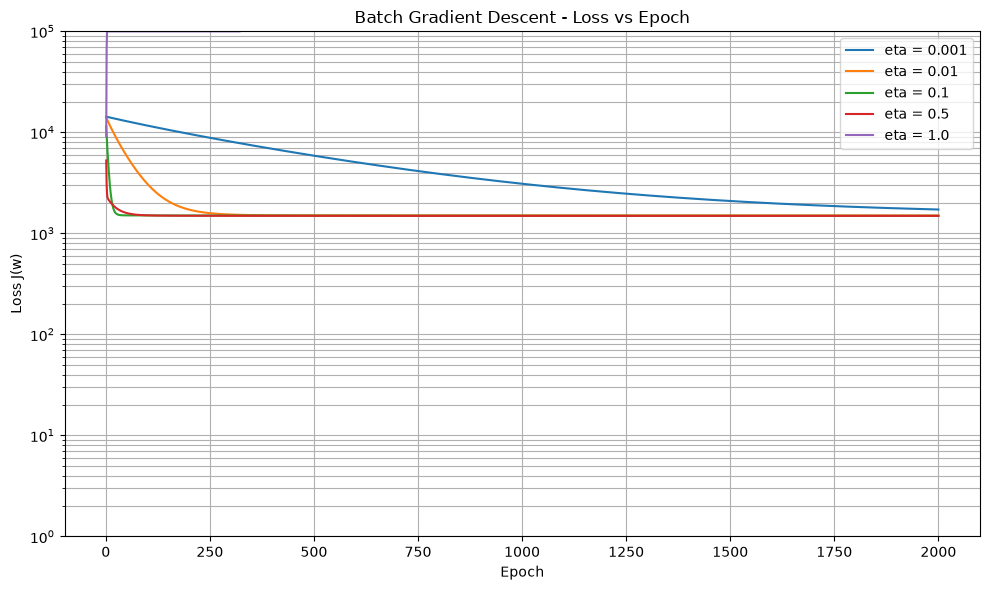

In [30]:
fig, ax = plt.subplots(figsize=(10, 6))
plot_cap = 100000

for eta, result in gd_results.items():

    losses = np.array(result["loss"], dtype=float)

    valid = np.isfinite(losses) & (losses > 0)
    epochs_axis = np.arange(1, len(losses) + 1)
    plotted_losses = np.minimum(losses[valid], plot_cap)

    ax.plot(epochs_axis[valid],plotted_losses,label=f"eta = {eta}")

ax.set_yscale("log")
ax.set_ylim(1, plot_cap)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss J(w)")
ax.set_title("Batch Gradient Descent - Loss vs Epoch")
ax.legend()
ax.grid(True, which="both")
plt.tight_layout()
plt.show()


Interpretation: Small learning rates (0.001 and 0.01) converge slowly because their updates are small. A learning rate of 0.5 reaches the required relative distance threshold within 1524 epochs, while 0.1 gets close but does not reach the threshold. However, a learning rate of 1.0 causes divergence because the updates are too large.

In [31]:
#Hessian matrix
H = (X_train_bias.T @ X_train_bias) / N
#eigenvalues
eigenvalues = np.linalg.eigvalsh(H)
#Largest
lambda_max = eigenvalues[-1]
#rate limit
eta_max = 2 / lambda_max

print("Lambda max:", lambda_max)
print("Maximum learning rate:", eta_max)

Lambda max: 3.9547550320503744
Maximum learning rate: 0.5057203249737277


In [32]:

# BEGIN AI-GENERATED CODE
test_learning_rates = {
    "Below threshold (0.95)": 0.95 * eta_max,
    "Above threshold (1.05)": 1.05 * eta_max
}

test_results = {}

for name, eta in test_learning_rates.items():

    w = np.zeros(X_train_bias.shape[1])
    loss_history = []
    distance_history = []
    diverged = False

    for epoch in range(1, 2001):
        y_pred = X_train_bias @ w
        gradient = (X_train_bias.T @ (y_pred - y_train)) / N
        w = w - eta * gradient

        if not np.all(np.isfinite(w)):
            diverged = True
            break

        y_pred = X_train_bias @ w
        J = 0.5 * np.mean((y_pred - y_train) ** 2)

        if not np.isfinite(J):
            diverged = True
            break

        distance = np.linalg.norm(w - w_star) / np.linalg.norm(w_star)

        if not np.isfinite(distance):
            diverged = True
            break

        loss_history.append(J)
        distance_history.append(distance)

        if len(loss_history) > 1:
           if loss_history[-1] > loss_history[0]:
                diverged = True

    test_results[name] = {
        "eta": eta,
        "loss": loss_history,
        "distance": distance_history,
        "diverged": diverged
    }

for name, result in test_results.items():

    print("\n", name)
    print("Learning rate:", result["eta"])
    print("Diverged:", result["diverged"])

    if result["loss"]:
        print("Final Loss:", result["loss"][-1])
        print("Final Relative Distance:", result["distance"][-1])



 Below threshold (0.95)
Learning rate: 0.4804343087250412
Diverged: False
Final Loss: 1491.145909733976
Final Relative Distance: 0.0002102307531542578

 Above threshold (1.05)
Learning rate: 0.5310063412224141
Diverged: True
Final Loss: 3.244811817873049e+168
Final Relative Distance: 7.581863342445143e+81


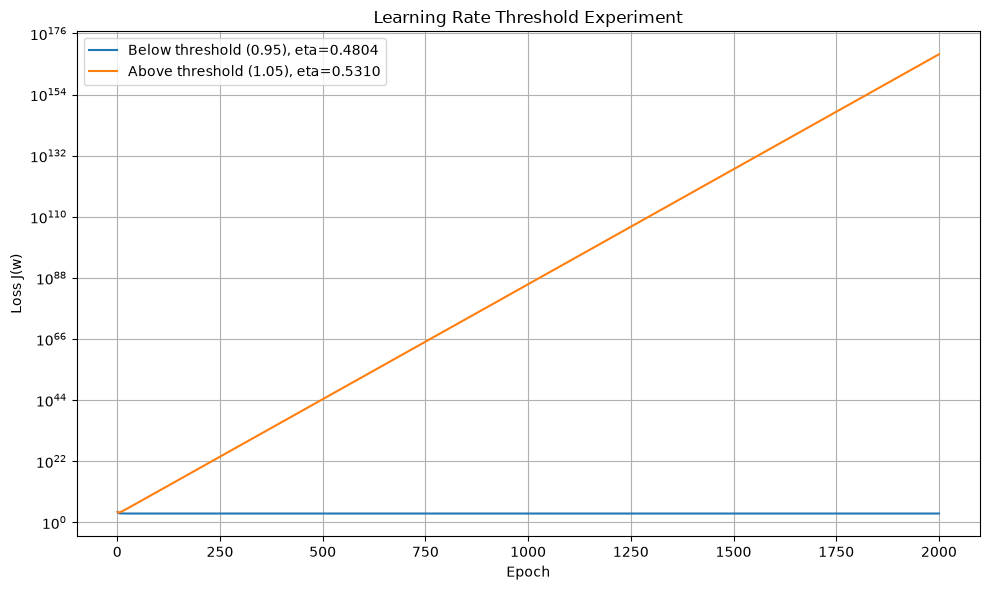

In [33]:
plt.figure(figsize=(10, 6))
for name, result in test_results.items():

    losses = np.array(result["loss"])

    plt.plot(
        np.arange(1, len(losses) + 1),
        losses,
        label=f"{name}, eta={result['eta']:.4f}"
    )

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss J(w)")
plt.title("Learning Rate Threshold Experiment")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Interpretation: The experiment confirms the theoretical learning rate limit. When the learning rate is set to 0.95 times the maximum allowed value, Gradient Descent converges and the loss stabilizes near its minimum. However, when the learning rate is set to 1.05 times the maximum allowed value, the loss increases rapidly, causing divergence. This demonstrates that the learning rate must remain below (2/lambda_max(H)) for convergence.

In [34]:

#unstandardized
X_train_raw, X_val_raw, X_test_raw, y_train_raw, y_val_raw, y_test_raw = splits["Diabetes"]
#bias column
X_train_raw_bias = add_bias(X_train_raw)
#training samples
N_raw = len(y_train_raw)
w_star_raw = normal_equation(X_train_raw, y_train_raw)

In [35]:
H_raw = (X_train_raw_bias.T @ X_train_raw_bias) / N_raw
lambda_max_raw = np.linalg.eigvalsh(H_raw)[-1]
eta_max_raw = 2 / lambda_max_raw

condition_raw = np.linalg.cond(
    X_train_raw_bias.T @ X_train_raw_bias
)

X_train_std_bias = add_bias(X_train)

H_std = (X_train_std_bias.T @ X_train_std_bias) / len(y_train)
lambda_max_std = np.linalg.eigvalsh(H_std)[-1]
eta_max_std = 2 / lambda_max_std

condition_std = np.linalg.cond(X_train_std_bias.T @ X_train_std_bias)

print("Raw condition number:", condition_raw)
print("Standardized condition number:", condition_std)
print("\nRaw eta max:", eta_max_raw)
print("Standardized eta max:", eta_max_std)


Raw condition number: 55778473.21993696
Standardized condition number: 505.7061226961072

Raw eta max: 2.7427928748390996e-05
Standardized eta max: 0.5057203249737277


In [36]:
raw_learning_rates = [1e-8, 1e-6, 1e-5, 1e-4]
raw_epochs = 2000
raw_gd_results = {}

for eta in raw_learning_rates:

    w = np.zeros(X_train_raw_bias.shape[1])

    loss_history = []
    distance_history = []
    diverged = False

    for epoch in range(1, raw_epochs + 1):

        # Predictions
        with np.errstate(over="ignore", invalid="ignore"):
            y_pred = X_train_raw_bias @ w

        if not np.all(np.isfinite(y_pred)):
            diverged = True
            break

        # Gradient
        with np.errstate(over="ignore", invalid="ignore"):
            gradient = (
                X_train_raw_bias.T @ (y_pred - y_train_raw)
            ) / N_raw

        if not np.all(np.isfinite(gradient)):
            diverged = True
            break

        # Update weights
        with np.errstate(over="ignore", invalid="ignore"):
            w = w - eta * gradient

        if not np.all(np.isfinite(w)):
            diverged = True
            break

        #loss
        with np.errstate(over="ignore", invalid="ignore"):
            y_pred = X_train_raw_bias @ w
            J = 0.5 * np.mean((y_pred - y_train_raw) ** 2)

        if not np.isfinite(J):
            diverged = True
            break

        # Relative distance
        distance = (np.linalg.norm(w - w_star_raw) / np.linalg.norm(w_star_raw))

        if not np.isfinite(distance):
            diverged = True
            break

        loss_history.append(J)
        distance_history.append(distance)

    raw_gd_results[eta] = {
        "weights": w,
        "loss": loss_history,
        "distance": distance_history,
        "diverged": diverged
    }

In [37]:
raw_results_table = []
for eta, result in raw_gd_results.items():
    losses = result["loss"]
    distances = result["distance"]

    raw_results_table.append({
        "Learning Rate": eta,
        "Final J": losses[-1] if losses else np.nan,
        "Final Relative Distance": distances[-1] if distances else np.nan,
        "Diverged": result["diverged"]
    })
raw_gd_table = pd.DataFrame(raw_results_table)
print(raw_gd_table.to_string(index=False))

 Learning Rate       Final J  Final Relative Distance  Diverged
  1.000000e-08  3.583532e+03             9.999986e-01     False
  1.000000e-06  2.388753e+03             9.999676e-01     False
  1.000000e-05  1.827535e+03             9.998464e-01     False
  1.000000e-04 2.484752e+304            2.172173e+147      True


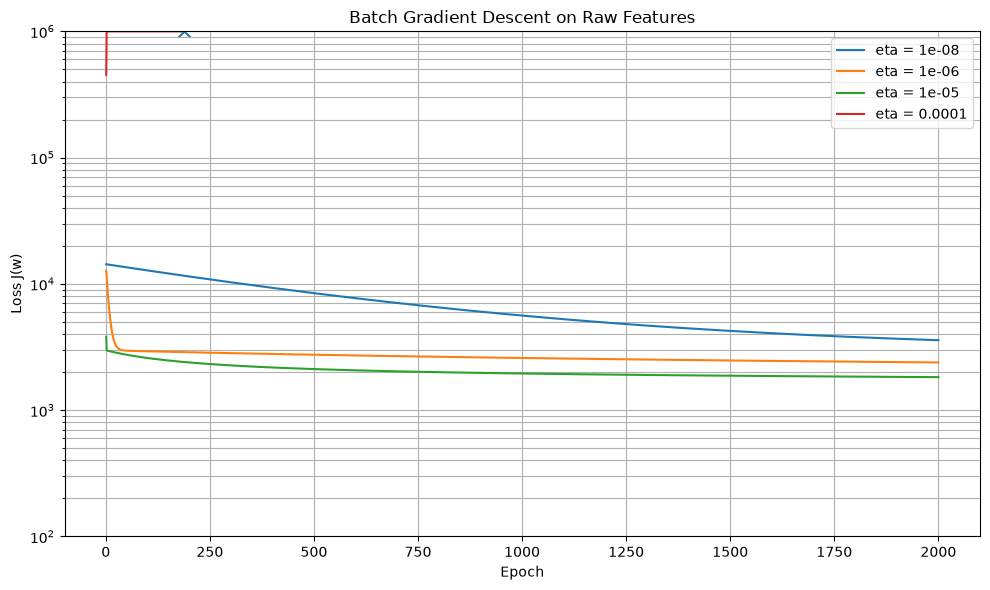

In [38]:

# BEGIN AI-GENERATED CODE
plt.figure(figsize=(10, 6))

# Visualization limit only; original results remain unchanged
plot_cap = 1e6

for eta, result in raw_gd_results.items():

    losses = np.array(result["loss"], dtype=float)

    # Keep finite positive values
    valid = np.isfinite(losses) & (losses > 0)

    epochs_axis = np.arange(1, len(losses) + 1)

    # Cap very large values for visualization
    plotted_losses = np.minimum(losses[valid], plot_cap)

    plt.plot(
        epochs_axis[valid],
        plotted_losses,
        label=f"eta = {eta}"
    )

    # Mark experiments that diverged
    if result["diverged"]:
        plt.scatter(
            epochs_axis[valid][-1],
            plotted_losses[-1],
            marker="x",
            s=80
        )

plt.yscale("log")
plt.ylim(1e2, plot_cap)
plt.xlabel("Epoch")
plt.ylabel("Loss J(w)")
plt.title("Batch Gradient Descent on Raw Features")
plt.legend()
plt.grid(True, which="both")
plt.tight_layout()
plt.show()
# END AI-GENERATED CODE

Interpretation: Without feature standardization, the condition number increases significantly from approximately 506 to 55.8 million, making the optimization problem more ill-conditioned. The maximum stable learning rate also decreases from approximately 0.506 to 0.0000274. The tested raw-feature learning rates converge very slowly, and none reaches the optimal solution within 2000 epochs, while a learning rate of 0.0001 causes divergence. This demonstrates that feature standardization improves numerical conditioning and allows Gradient Descent to use larger learning rates and converge more efficiently.

In [39]:
def mini_batch_gd(X, y, batch_size, eta, epochs=100):
    N = len(y)
    X_bias = add_bias(X)
    w = np.zeros(X_bias.shape[1])
    rng = np.random.default_rng(42)

    y_pred = X_bias @ w
    initial_loss = 0.5 * np.mean((y_pred - y) ** 2)

    loss_per_epoch = [initial_loss]
    loss_per_update = [initial_loss]

    for epoch in range(epochs):

        indices = rng.permutation(N)
        X_shuffled = X_bias[indices]
        y_shuffled = y[indices]

        for start in range(0, N, batch_size):
            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            y_pred_batch = X_batch @ w
            gradient = (X_batch.T @ (y_pred_batch - y_batch)) / len(y_batch)
            w = w - eta * gradient

            y_pred = X_bias @ w
            current_loss = 0.5 * np.mean((y_pred - y) ** 2)
            loss_per_update.append(current_loss)
        loss_per_epoch.append(current_loss)

    return w, loss_per_epoch, loss_per_update

In [40]:
batch_sizes = [1, 16, 64, len(y_train)]
eta = 0.01
epochs = 100
mini_batch_results = {}

for B in batch_sizes:
    w, epoch_losses, update_losses = mini_batch_gd(
        X_train,
        y_train,
        batch_size=B,
        eta=eta,
        epochs=epochs
    )

    mini_batch_results[B] = {
        "weights": w,
        "epoch_losses": epoch_losses,
        "update_losses": update_losses
    }

results_table = pd.DataFrame([
    {
        "Batch Size": B,
        "Final Training Loss": mini_batch_results[B]["epoch_losses"][-1],
        "Number of Updates": len(mini_batch_results[B]["update_losses"]) - 1
    }
    for B in batch_sizes
])
print(results_table.to_string(index=False))

 Batch Size  Final Training Loss  Number of Updates
          1          1534.808385              26400
         16          1505.665099               1700
         64          1511.375336                500
        264          3085.440479                100


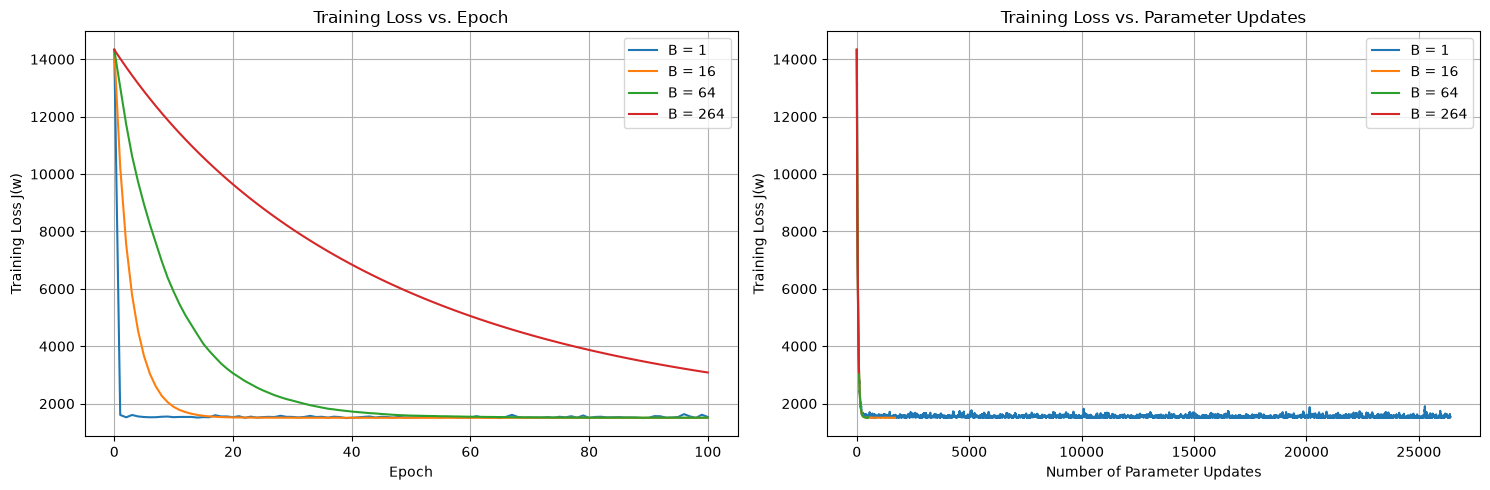

In [41]:

# BEGIN AI-GENERATED CODE

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for B in batch_sizes:
    result = mini_batch_results[B]

    # Loss against epochs
    axes[0].plot(
        range(len(result["epoch_losses"])),
        result["epoch_losses"],
        label=f"B = {B}"
    )

    # Loss against parameter updates
    axes[1].plot(
        range(len(result["update_losses"])),
        result["update_losses"],
        label=f"B = {B}"
    )

axes[0].set_title("Training Loss vs. Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training Loss J(w)")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Training Loss vs. Parameter Updates")
axes[1].set_xlabel("Number of Parameter Updates")
axes[1].set_ylabel("Training Loss J(w)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# END AI-GENERATED CODE


Comparison of Batch Sizes:

Best per epoch: B = 1 achieves the fastest initial decrease in training loss per epoch because it performs many parameter updates during each epoch. However, B = 16 achieves the lowest final training loss.

Best per update: B = 16 is the most effective choice in this experiment because it achieves a low training loss with significantly fewer parameter updates than B = 1.

Why is B = 1 noisier? Each update uses only one training sample, so the gradient depends heavily on that individual sample. As a result, the updates fluctuate more, producing a noisier optimization proc

In [42]:
learning_rates = [0.001, 0.01, 0.1]
stochastic_results = {}

for lr in learning_rates:
    w, epoch_losses, update_losses = mini_batch_gd(X_train,y_train,batch_size=1,eta=lr,epochs=10)

    stochastic_results[lr] = {
        "weights": w,
        "epoch_losses": epoch_losses,
        "update_losses": update_losses
    }

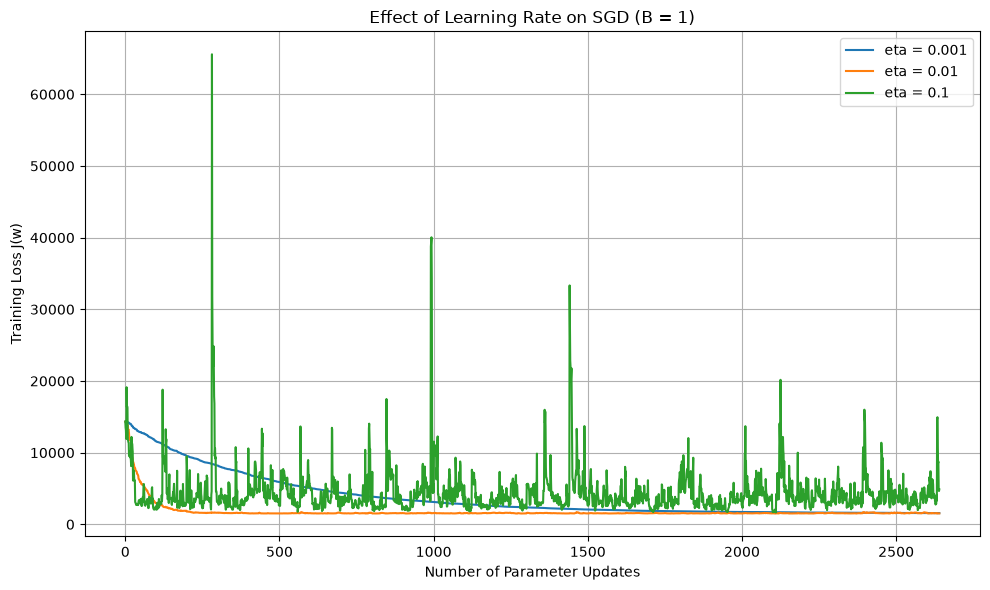

In [43]:

# BEGIN AI-GENERATED CODE

plt.figure(figsize=(10, 6))

for lr, result in stochastic_results.items():
    losses = np.array(result["update_losses"], dtype=float)
    updates = np.arange(len(losses))

    valid = np.isfinite(losses) & (losses > 0)

    plt.plot(
        updates[valid],
        losses[valid],
        label=f"eta = {lr}"
    )

plt.xlabel("Number of Parameter Updates")
plt.ylabel("Training Loss J(w)")
plt.title("Effect of Learning Rate on SGD (B = 1)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# END AI-GENERATED CODE

Interpretation:
Increasing the learning rate from 0.001 to 0.01 improves the convergence speed of SGD while maintaining relatively stable updates. However, increasing it further to 0.1 causes large fluctuations in the training loss, making the optimization process much noisier and less stable. Therefore, η = 0.01 provides the best balance between convergence speed and stability in this experiment. This demonstrates that a larger learning rate does not always lead to better optimization.

In [44]:
def ridge_closed_form(X, y, lam):
    N = len(y)
    X_bias = add_bias(X)

    I0 = np.eye(X_bias.shape[1])

    I0[0, 0] = 0

    A = (X_bias.T @ X_bias) / N + lam * I0
    b = (X_bias.T @ y) / N

    w = np.linalg.solve(A, b)

    return w

X_example = np.array([[1], [2], [3]], dtype=float)
y_example = np.array([2, 3, 5], dtype=float)

w_ridge_example = ridge_closed_form(X_example,y_example,lam=1)
print("Ridge weights:", w_ridge_example)

Ridge weights: [2.13333333 0.6       ]


In [45]:
X_train_raw, X_val_raw, X_test_raw, y_train, y_val, y_test = splits["Diabetes"]

print("Training shape:", X_train_raw.shape)
print("Validation shape:", X_val_raw.shape)
print("Test shape:", X_test_raw.shape)

Training shape: (264, 10)
Validation shape: (89, 10)
Test shape: (89, 10)


In [46]:
def polynomial_features_degree2(X):
    n_samples, n_features = X.shape
    polynomial_columns = [X[:, i] for i in range(n_features)]
    for i in range(n_features):
        for j in range(i, n_features):

            if i == 1 and j == 1:
                continue

            polynomial_columns.append(X[:, i] * X[:, j])

    return np.column_stack(polynomial_columns)


X_train_poly = polynomial_features_degree2(X_train_raw)
X_val_poly = polynomial_features_degree2(X_val_raw)
X_test_poly = polynomial_features_degree2(X_test_raw)
print("Original features:", X_train_raw.shape[1])
print("Polynomial features:", X_train_poly.shape[1])

Original features: 10
Polynomial features: 64


In [47]:
poly_mean = np.mean(X_train_poly, axis=0)
poly_std = np.std(X_train_poly, axis=0)
poly_std[poly_std == 0] = 1

X_train_poly_std = (X_train_poly - poly_mean) / poly_std
X_val_poly_std = (X_val_poly - poly_mean) / poly_std
X_test_poly_std = (X_test_poly - poly_mean) / poly_std

print("Standardized training shape:", X_train_poly_std.shape)
print("Standardized validation shape:", X_val_poly_std.shape)
print("Standardized test shape:", X_test_poly_std.shape)

Standardized training shape: (264, 64)
Standardized validation shape: (89, 64)
Standardized test shape: (89, 64)


In [48]:
lambda_values = np.concatenate(([0], np.logspace(-3, 1, 9)))
ridge_results = {}
for lam in lambda_values:
    w = ridge_closed_form(X_train_poly_std, y_train, lam)
    X_val_bias = add_bias(X_val_poly_std)
    y_val_pred = X_val_bias @ w
    val_rmse = rmse(y_val, y_val_pred)

    ridge_results[lam] = {
        "weights": w,
        "val_rmse": val_rmse
    }

ridge_table = pd.DataFrame([
    {
        "Lambda": lam,
        "Validation RMSE": ridge_results[lam]["val_rmse"]
    }
    for lam in lambda_values
])

print(ridge_table.to_string(index=False))

best_lambda = min(ridge_results,key=lambda lam: ridge_results[lam]["val_rmse"])
print("\nBest Lambda:", best_lambda)
print("Best Validation RMSE:", ridge_results[best_lambda]["val_rmse"])


   Lambda  Validation RMSE
 0.000000        59.205949
 0.001000        54.207871
 0.003162        53.053194
 0.010000        52.106089
 0.031623        51.474170
 0.100000        51.270640
 0.316228        51.316252
 1.000000        51.497243
 3.162278        52.630193
10.000000        56.640332

Best Lambda: 0.1
Best Validation RMSE: 51.27063977293424


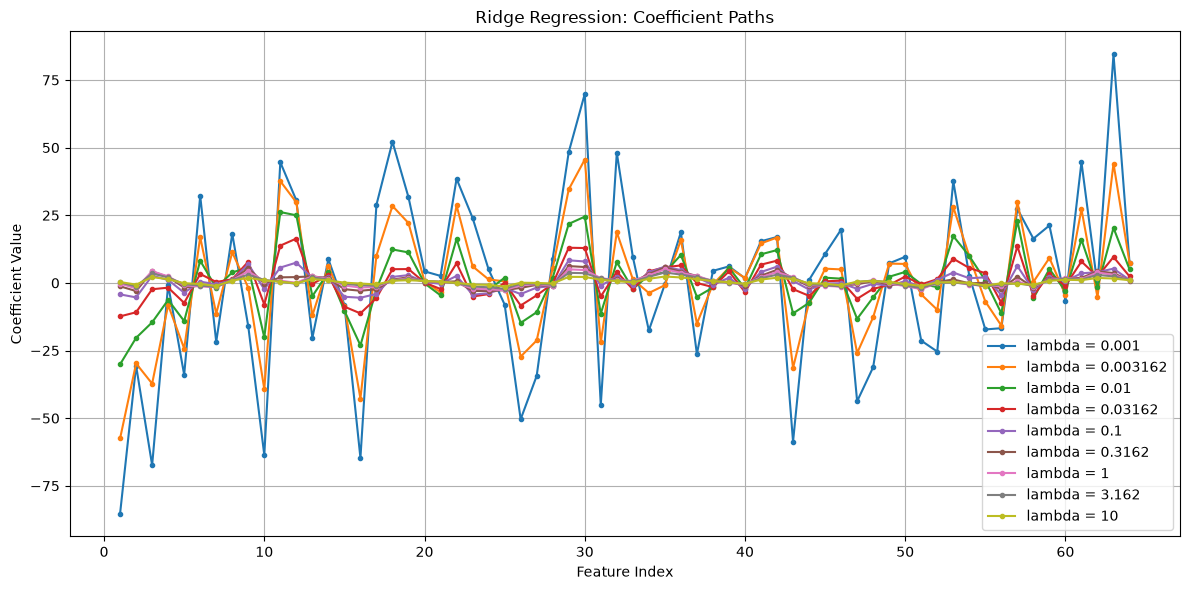

In [49]:
plt.figure(figsize=(12, 6))

for lam in lambda_values:
    if lam == 0:
        continue

    weights = ridge_results[lam]["weights"]

    plt.plot(np.arange(1, len(weights)),weights[1:],marker=".",label=f"lambda = {lam:.4g}")

plt.xlabel("Feature Index")
plt.ylabel("Coefficient Value")
plt.title("Ridge Regression: Coefficient Paths")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


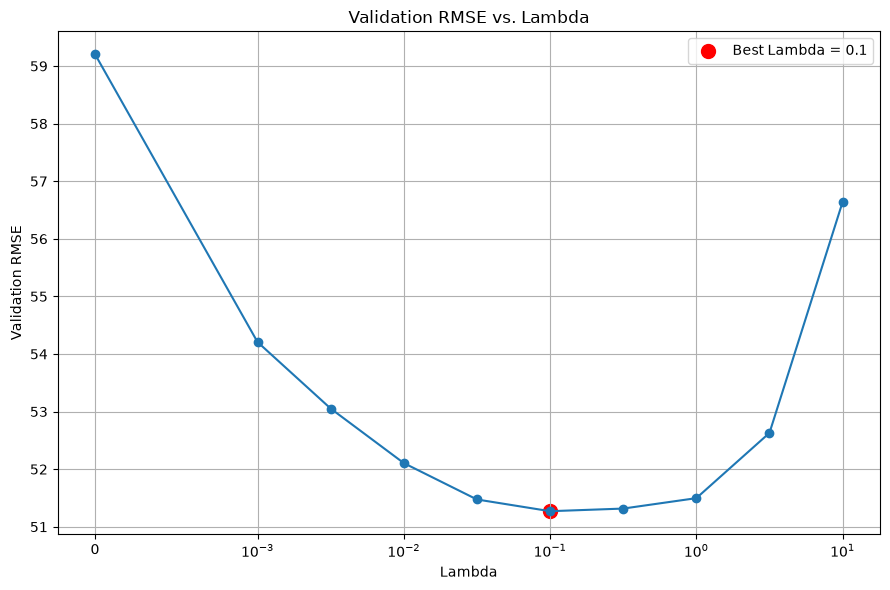

In [50]:
plt.figure(figsize=(9, 6))
plt.plot(lambda_values,[ridge_results[lam]["val_rmse"] for lam in lambda_values],marker="o")
plt.xscale("symlog", linthresh=0.001)

plt.scatter(
    best_lambda,
    ridge_results[best_lambda]["val_rmse"],
    color="red",
    s=100,
    label=f"Best Lambda = {best_lambda}"
)

plt.xlabel("Lambda")
plt.ylabel("Validation RMSE")
plt.title("Validation RMSE vs. Lambda")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [51]:

X_test_poly_bias = add_bias(X_test_poly_std)

#without regularization
w_no_reg = ridge_results[0.0]["weights"]
y_test_pred_no_reg = X_test_poly_bias @ w_no_reg
test_rmse_no_reg = rmse(y_test, y_test_pred_no_reg)

#with best lambda
w_best = ridge_results[best_lambda]["weights"]
y_test_pred_ridge = X_test_poly_bias @ w_best
test_rmse_ridge = rmse(y_test, y_test_pred_ridge)

print("Test RMSE without regularization:", test_rmse_no_reg)
print("Test RMSE with Ridge (lambda =", best_lambda, "):", test_rmse_ridge)

Test RMSE without regularization: 62.133373394094434
Test RMSE with Ridge (lambda = 0.1 ): 53.61558011674492


In [52]:
X_train_original, X_val_original, X_test_original, y_train, y_val, y_test = standardized_splits["Diabetes"]

lam = 0.1
eta = 0.4
epochs = 3000

X_train_original_bias = add_bias(X_train_original)
N = len(y_train)

w_closed_original = ridge_closed_form(X_train_original, y_train, lam)
w_gd_original = np.zeros(X_train_original_bias.shape[1])

I0 = np.eye(len(w_gd_original))
I0[0, 0] = 0

for epoch in range(epochs):

    y_pred = X_train_original_bias @ w_gd_original

    gradient = (X_train_original_bias.T @ (y_pred - y_train)) / N

    gradient += lam * (I0 @ w_gd_original)

    w_gd_original = w_gd_original - eta * gradient

# Calculate relative distance
relative_distance = (np.linalg.norm(w_gd_original - w_closed_original) / np.linalg.norm(w_closed_original))
print("Relative distance:", relative_distance)

Relative distance: 9.224192790282157e-16


In [53]:
from sklearn.linear_model import Ridge
sk_ridge_original = Ridge(alpha=lam * len(y_train),fit_intercept=True)
sk_ridge_original.fit(X_train_original, y_train)

w_sklearn_original = np.concatenate(([sk_ridge_original.intercept_],sk_ridge_original.coef_))
max_difference_original = np.max(np.abs(w_closed_original - w_sklearn_original))
print("Maximum absolute weight difference:", max_difference_original)

Maximum absolute weight difference: 1.4477308241112041e-13


The Gradient Descent implementation successfully converged to the closed-form Ridge solution, with a relative distance of 9.22e-16, which is below the required threshold of 1e-6. The closed-form implementation was also verified against Scikit-learn's Ridge Regression, with a maximum absolute weight difference of 1.45e-13.

In [54]:
lambda_values = np.concatenate(([0.0], np.logspace(-3, 1, 9)))
ridge_results_original = {}

for lam_value in lambda_values:
    w = ridge_closed_form(X_train_original, y_train, lam_value)
    X_val_original_bias = add_bias(X_val_original)
    y_val_pred = X_val_original_bias @ w
    val_rmse = rmse(y_val, y_val_pred)

    ridge_results_original[lam_value] = {
        "weights": w,
        "val_rmse": val_rmse
    }

print("Lambda\t\tValidation RMSE")

for lam_value in lambda_values:
    print(
        f"{lam_value:.6f}\t{ridge_results_original[lam_value]['val_rmse']:.6f}"
    )

Lambda		Validation RMSE
0.000000	51.193714
0.001000	51.149556
0.003162	51.108041
0.010000	51.104749
0.031623	51.153130
0.100000	51.207305
0.316228	51.577988
1.000000	53.695124
3.162278	59.420332
10.000000	66.954649


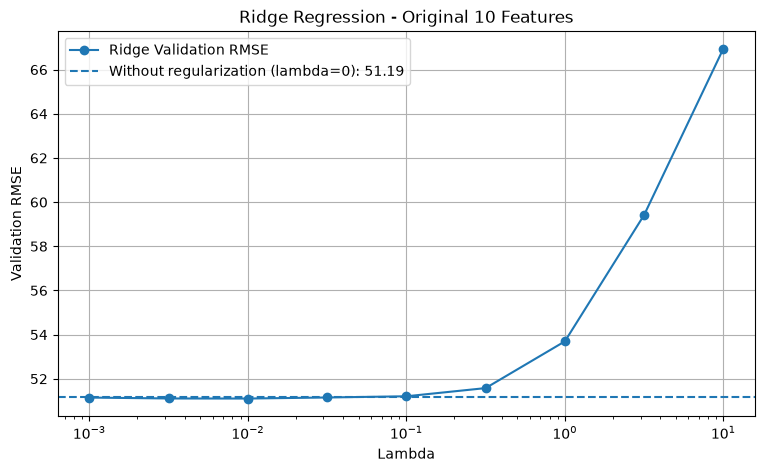

In [55]:

# BEGIN AI-GENERATED CODE

positive_lambdas = lambda_values[1:]

val_errors = [
    ridge_results_original[lam]["val_rmse"]
    for lam in positive_lambdas
]

zero_rmse = ridge_results_original[0.0]["val_rmse"]

plt.figure(figsize=(9, 5))

plt.plot(
    positive_lambdas,
    val_errors,
    marker="o",
    label="Ridge Validation RMSE"
)

plt.axhline(
    y=zero_rmse,
    linestyle="--",
    label=f"Without regularization (lambda=0): {zero_rmse:.2f}"
)

plt.xscale("log")
plt.xlabel("Lambda")
plt.ylabel("Validation RMSE")
plt.title("Ridge Regression - Original 10 Features")
plt.legend()
plt.grid(True)
plt.show()

# END AI-GENERATED CODE

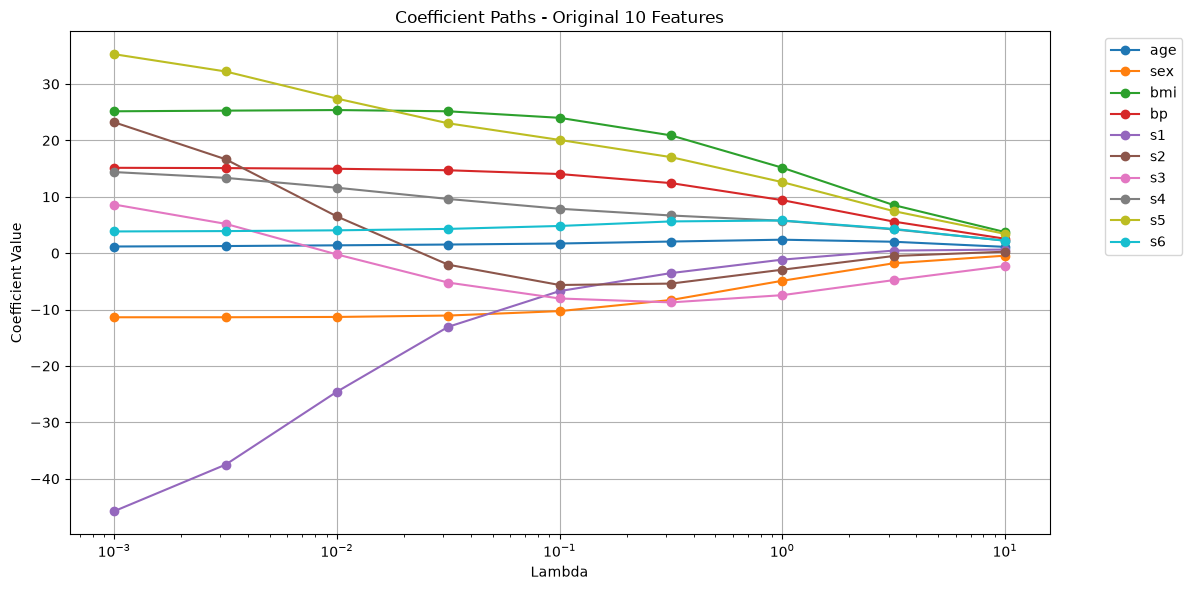

In [56]:

# BEGIN AI-GENERATED CODE

feature_names = load_diabetes(scaled=False).feature_names

plt.figure(figsize=(12, 6))

for i in range(1, len(ridge_results_original[positive_lambdas[0]]["weights"])):
    coefficients = [
        ridge_results_original[lam]["weights"][i]
        for lam in positive_lambdas
    ]

    plt.plot(
        positive_lambdas,
        coefficients,
        marker="o",
        label=feature_names[i - 1]
    )

plt.xscale("log")
plt.xlabel("Lambda")
plt.ylabel("Coefficient Value")
plt.title("Coefficient Paths - Original 10 Features")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()

# END AI-GENERATED CODE


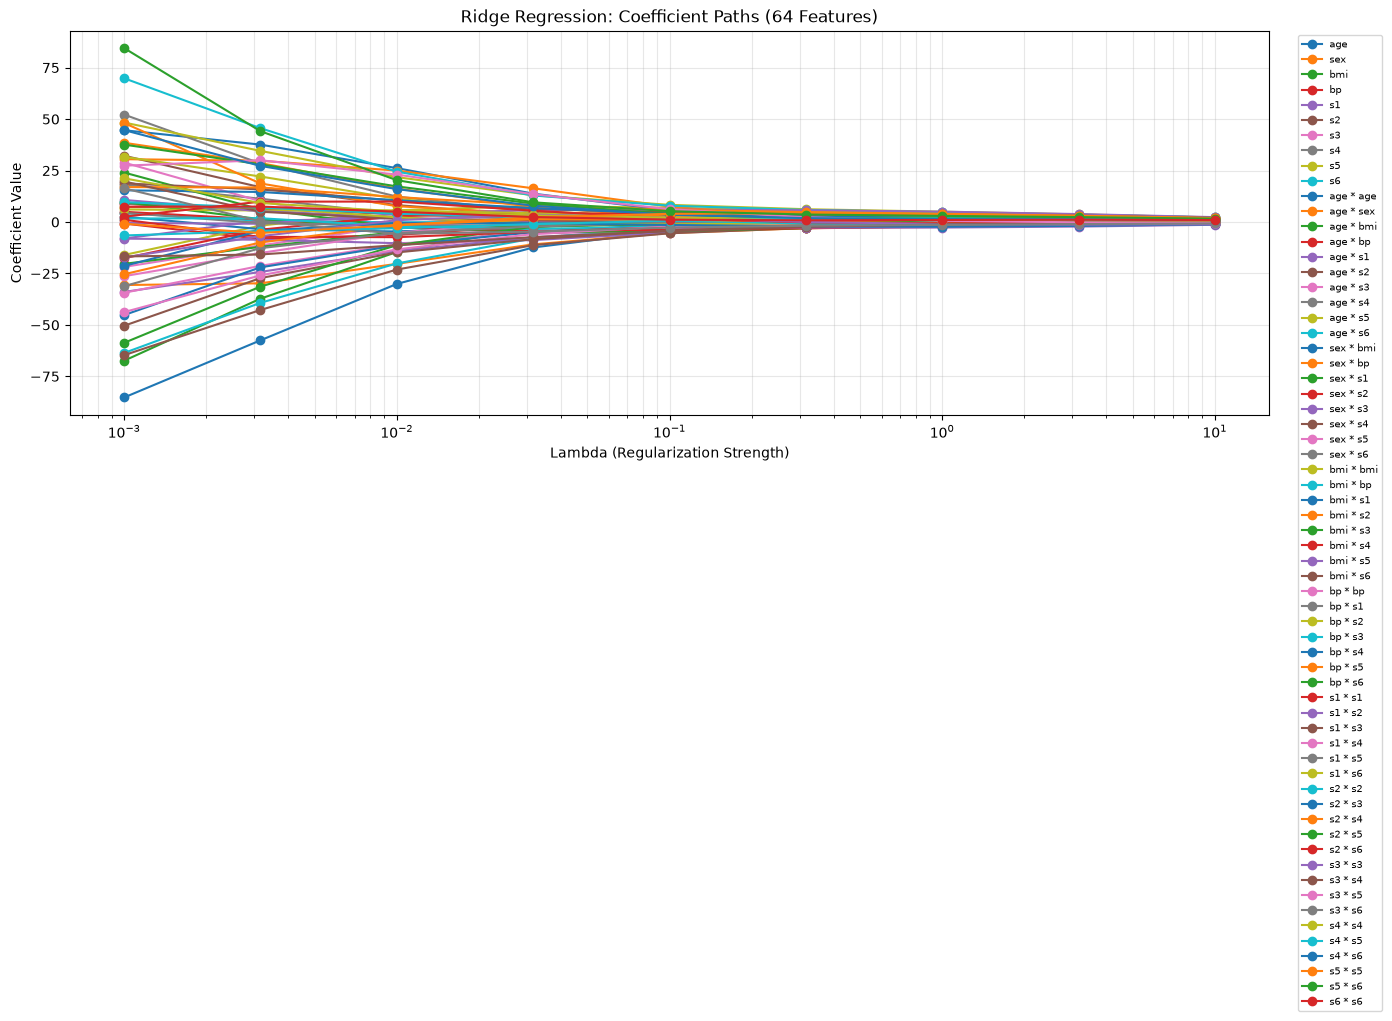

Number of polynomial features: 64
Expected number of coefficients: 64


In [72]:

# Ridge Coefficient Paths for 64 Polynomial Features

feature_names = list(diabetes.feature_names)

# Generate names in the same order as polynomial_features_degree2()
poly_feature_names = feature_names.copy()

for i in range(len(feature_names)):
    for j in range(i, len(feature_names)):

        # Skip sex^2 because it is redundant
        if i == 1 and j == 1:
            continue

        poly_feature_names.append(
            f"{feature_names[i]} * {feature_names[j]}"
        )

# Exclude lambda = 0 because the x-axis uses logarithmic scale
positive_lambdas = lambda_values[1:]

plt.figure(figsize=(14, 8))

# Plot every coefficient against lambda
for i, feature_name in enumerate(poly_feature_names):

    coefficients = [
        ridge_results[lam]["weights"][i + 1]
        for lam in positive_lambdas
    ]

    plt.plot(
        positive_lambdas,
        coefficients,
        marker="o",
        linewidth=1.5,
        label=feature_name
    )

plt.xscale("log")

plt.xlabel("Lambda (Regularization Strength)")
plt.ylabel("Coefficient Value")
plt.title("Ridge Regression: Coefficient Paths (64 Features)")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=7,
    ncol=1
)

plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

print("Number of polynomial features:", len(poly_feature_names))
print("Expected number of coefficients:", len(ridge_results[positive_lambdas[0]]["weights"]) - 1)


In [57]:
X_train_poly_bias = add_bias(X_train_poly_std)
condition_number_poly = np.linalg.cond(X_train_poly_bias.T @ X_train_poly_bias)
print("Polynomial Features Condition Number:", condition_number_poly)

Polynomial Features Condition Number: 1289356242.9009633


##### Ridge Regression: Why is the gain from ridge small in (i) nut large in (ii) (N versus d), and why must the bias not be penalized.

1. Ridge regularization provides only a small improvement on the 10 original features because the number of training samples (264) is relatively large compared with the number of features (10), so the original model is less prone to overfitting.

2. In contrast, the degree-2 polynomial expansion increases the number of features to 64, making the model more complex and increasing the risk of overfitting with the available training data.

3. Ridge regularization reduces the magnitude of the coefficients, helping control model complexity and improve generalization. This explains the larger improvement in validation and test RMSE for the polynomial model.

4. The bias term should not be penalized because it represents the baseline prediction level. Penalizing it would unnecessarily force the baseline toward zero and could introduce unwanted prediction bias.

In [58]:
import time
from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor
X_train_10 = X_train_original
X_test_10 = X_test_original
X_train_bias_10 = add_bias(X_train_10)
X_test_bias_10 = add_bias(X_test_10)

N_train = len(y_train)
w_star = normal_equation(X_train_10, y_train)
comparison_results = []

def evaluate_model(name, weights, fit_time):
    y_test_pred = X_test_bias_10 @ weights
    test_error = rmse(y_test, y_test_pred)
    relative_distance = (np.linalg.norm(weights - w_star)/ np.linalg.norm(w_star))

    comparison_results.append({
        "Method": name,
        "Test RMSE": test_error,
        "Relative Distance": relative_distance,
        "Fit Time (seconds)": fit_time
    })

# Normal Equation - From Scratch
start_time = time.perf_counter()
w_normal = normal_equation(X_train_10, y_train)
normal_time = time.perf_counter() - start_time

evaluate_model("Normal Equation", w_normal, normal_time)

# Linear Regression - Scikit-learn
linear_model = LinearRegression()
start_time = time.perf_counter()
linear_model.fit(X_train_10, y_train)
linear_time = time.perf_counter() - start_time
w_linear = np.concatenate(([linear_model.intercept_],linear_model.coef_))

evaluate_model("LinearRegression", w_linear, linear_time)


# Batch Gradient Descent - From Scratch
eta = 0.5
epochs = 2000
w_batch = np.zeros(X_train_bias_10.shape[1])
start_time = time.perf_counter()

for epoch in range(epochs):

    y_pred = X_train_bias_10 @ w_batch
    gradient = (X_train_bias_10.T @ (y_pred - y_train)) / N_train
    w_batch = w_batch - eta * gradient

batch_time = time.perf_counter() - start_time

evaluate_model("Batch GD", w_batch, batch_time)

# Mini-batch Gradient Descent - From Scratch
start_time = time.perf_counter()
w_mini, epoch_losses, update_losses = mini_batch_gd(X_train_10,y_train,batch_size=16,eta=0.01,epochs=100)
mini_time = time.perf_counter() - start_time

evaluate_model("Mini-batch GD", w_mini, mini_time)

# Ridge Regression - From Scratch
lam = 0.1
start_time = time.perf_counter()
w_ridge = ridge_closed_form(X_train_10, y_train, lam)
ridge_time = time.perf_counter() - start_time

evaluate_model("Ridge (Scratch)", w_ridge, ridge_time)

# Ridge Regression - Scikit-learn
ridge_model = Ridge(alpha=lam * N_train,fit_intercept=True)

start_time = time.perf_counter()
ridge_model.fit(X_train_10, y_train)
ridge_sklearn_time = time.perf_counter() - start_time
w_ridge_sklearn = np.concatenate(([ridge_model.intercept_],ridge_model.coef_))

evaluate_model("Ridge (sklearn)",w_ridge_sklearn,ridge_sklearn_time)


# SGDRegressor - Scikit-learn
for eta0 in [0.001, 0.01, 0.1]:

    sgd_model = SGDRegressor(penalty=None,learning_rate="constant",eta0=eta0,max_iter=1000,tol=None,random_state=42)
    start_time = time.perf_counter()
    sgd_model.fit(X_train_10, y_train)
    sgd_time = time.perf_counter() - start_time
    w_sgd = np.concatenate(([sgd_model.intercept_[0]],sgd_model.coef_))

    evaluate_model(f"SGDRegressor (eta0={eta0})",w_sgd,sgd_time)

comparison_table = pd.DataFrame(comparison_results)

print(comparison_table.to_string(index=False))

                   Method  Test RMSE  Relative Distance  Fit Time (seconds)
          Normal Equation  54.156413       0.000000e+00            0.000588
         LinearRegression  54.156413       8.053770e-15            0.004256
                 Batch GD  54.156254       1.546262e-04            0.037184
            Mini-batch GD  53.895449       3.421471e-01            0.057939
          Ridge (Scratch)  53.708925       3.636136e-01            0.000295
          Ridge (sklearn)  53.708925       3.636136e-01            0.001900
SGDRegressor (eta0=0.001)  54.088486       4.976050e-02            0.022660
 SGDRegressor (eta0=0.01)  54.898061       5.031993e-02            0.022591
  SGDRegressor (eta0=0.1)  71.449348       3.949685e-01            0.022088


In [59]:
print("Normal Equation vs LinearRegression:",np.max(np.abs(w_normal - w_linear)))
print("Ridge Scratch vs Ridge sklearn:",np.max(np.abs(w_ridge - w_ridge_sklearn)))

Normal Equation vs LinearRegression: 9.734435479913373e-13
Ridge Scratch vs Ridge sklearn: 1.4477308241112041e-13


##### In three sentences: where do library and from-scratch results agree exactly, where not, and why?
The Normal Equation and Scikit-learn's LinearRegression produce almost identical results because both solve the same unregularized least-squares problem. Similarly, our Ridge implementation and Scikit-learn's Ridge agree to numerical precision because both use the same regularization strength and do not penalize the intercept; however, gradient-based methods may differ due to finite iterations and stochastic updates. Finally, SGDRegressor with a learning rate of 0.1 performs significantly worse than with 0.001 because the larger learning rate causes unstable updates and makes it harder to converge.

Part C

In [60]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

# Get the standardized Breast Cancer data from Part A
X_train, X_val, X_test, y_train, y_val, y_test = standardized_splits["Breast Cancer"]

y_train = np.asarray(y_train).ravel()
y_val = np.asarray(y_val).ravel()
y_test = np.asarray(y_test).ravel()

# Add the bias column
X_train_b = np.c_[np.ones(len(X_train)), X_train]
X_val_b = np.c_[np.ones(len(X_val)), X_val]
X_test_b = np.c_[np.ones(len(X_test)), X_test]


def sigmoid(z):
    """Numerically stable sigmoid."""
    result = np.empty_like(z, dtype=float)

    positive = z >= 0
    result[positive] = 1 / (1 + np.exp(-z[positive]))

    exp_z = np.exp(z[~positive])
    result[~positive] = exp_z / (1 + exp_z)

    return result


def logistic_loss(X, y, w):
    """Mean data loss, without regularization."""
    z = X @ w
    return np.mean(np.logaddexp(0, z) - y * z)


def logistic_objective(X, y, w, lam):
    """Mean loss plus L2 regularization; bias is not regularized."""
    return logistic_loss(X, y, w) + (lam / 2) * np.sum(w[1:] ** 2)


def logistic_gradient(X, y, w, lam):
    p = sigmoid(X @ w)

    grad = X.T @ (p - y) / len(y)
    grad[1:] += lam * w[1:]

    return grad


# Stable loss example: z = +800 and z = -800
for z in [800.0, -800.0]:
    for y in [0, 1]:
        with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
            p = 1 / (1 + np.exp(-z))
            naive_loss = -(y * np.log(p) + (1-y) * np.log(1-p))

        stable_loss = np.logaddexp(0, z) - y * z

        print(f"z={z:5.0f}, y={y}: naive={naive_loss}, stable={stable_loss}")


# Gradient check with lambda = 0.1
rng = np.random.default_rng(42)
w_random = rng.normal(0, 0.1, X_train_b.shape[1])

lam = 0.1

relative_error = grad_check(
    lambda w: logistic_objective(X_train_b, y_train, w, lam),
    lambda w: logistic_gradient(X_train_b, y_train, w, lam),
    w_random
)

print("Gradient relative error:", relative_error)
assert relative_error < 1e-6


z=  800, y=0: naive=inf, stable=800.0
z=  800, y=1: naive=nan, stable=0.0
z= -800, y=0: naive=nan, stable=0.0
z= -800, y=1: naive=inf, stable=800.0
Gradient relative error: 1.7775135713047355e-11


In [61]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

# Get the standardized Breast Cancer data from Part A
X_train, X_val, X_test, y_train, y_val, y_test = standardized_splits["Breast Cancer"]

y_train = np.asarray(y_train).ravel()
y_val = np.asarray(y_val).ravel()
y_test = np.asarray(y_test).ravel()

# Add the bias column
X_train_b = np.c_[np.ones(len(X_train)), X_train]
X_val_b = np.c_[np.ones(len(X_val)), X_val]
X_test_b = np.c_[np.ones(len(X_test)), X_test]


def sigmoid(z):
    """Numerically stable sigmoid."""
    result = np.empty_like(z, dtype=float)

    positive = z >= 0
    result[positive] = 1 / (1 + np.exp(-z[positive]))

    exp_z = np.exp(z[~positive])
    result[~positive] = exp_z / (1 + exp_z)

    return result


def logistic_loss(X, y, w):
    """Mean data loss, without regularization."""
    z = X @ w
    return np.mean(np.logaddexp(0, z) - y * z)


def logistic_objective(X, y, w, lam):
    """Mean loss plus L2 regularization; bias is not regularized."""
    return logistic_loss(X, y, w) + (lam / 2) * np.sum(w[1:] ** 2)


def logistic_gradient(X, y, w, lam):
    p = sigmoid(X @ w)

    grad = X.T @ (p - y) / len(y)
    grad[1:] += lam * w[1:]

    return grad


# Stable loss example: z = +800 and z = -800
for z in [800.0, -800.0]:
    for y in [0, 1]:
        with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
            p = 1 / (1 + np.exp(-z))
            naive_loss = -(y * np.log(p) + (1-y) * np.log(1-p))

        stable_loss = np.logaddexp(0, z) - y * z

        print(f"z={z:5.0f}, y={y}: naive={naive_loss}, stable={stable_loss}")


# Gradient check with lambda = 0.1
rng = np.random.default_rng(42)
w_random = rng.normal(0, 0.1, X_train_b.shape[1])

lam = 0.1

relative_error = grad_check(
    lambda w: logistic_objective(X_train_b, y_train, w, lam),
    lambda w: logistic_gradient(X_train_b, y_train, w, lam),
    w_random
)

print("Gradient relative error:", relative_error)
assert relative_error < 1e-6


z=  800, y=0: naive=inf, stable=800.0
z=  800, y=1: naive=nan, stable=0.0
z= -800, y=0: naive=nan, stable=0.0
z= -800, y=1: naive=inf, stable=800.0
Gradient relative error: 1.7775135713047355e-11


,Lambda,Train Accuracy,Validation Accuracy,Validation Loss,Weight Norm
0,0.000,0.994135,0.973684,0.084192,8.132231
1,0.001,0.988270,0.973684,0.073203,5.099928
2,0.010,0.985337,0.973684,0.082964,2.325749
3,0.100,0.973607,0.973684,0.141553,1.105547
4,1.000,0.938416,0.956140,0.292213,0.441485


Best lambda: 0.001
Test accuracy: 0.9736842105263158


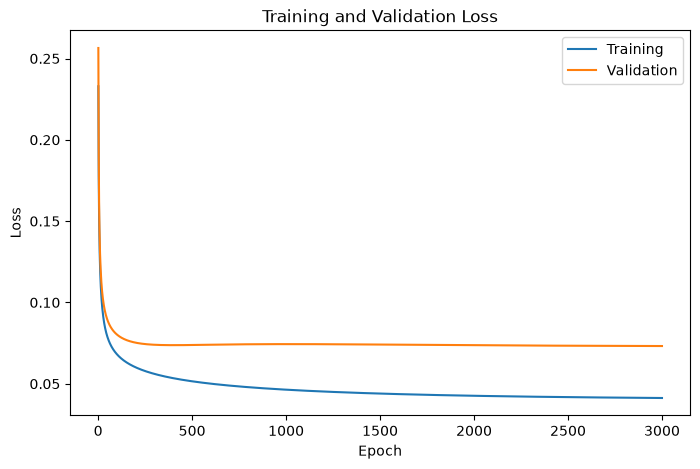

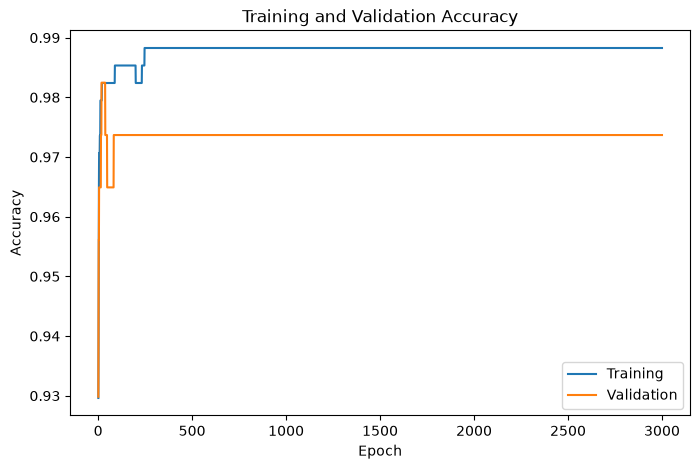

,Learning Rate,Final Training Loss
0,0.01,0.105222
1,0.10,0.072909
2,1.00,0.071066
3,5.00,0.071066
4,20.00,0.649280


In [62]:

def accuracy(y, pred):
    return np.mean(y == pred)


def train_logistic(X, y, X_val, y_val, lam, eta, epochs):
    w = np.zeros(X.shape[1])

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "weight_norm": []
    }

    for epoch in range(epochs):
        grad = logistic_gradient(X, y, w, lam)
        w -= eta * grad

        train_p = sigmoid(X @ w)
        val_p = sigmoid(X_val @ w)

        history["train_loss"].append(logistic_loss(X, y, w))
        history["val_loss"].append(logistic_loss(X_val, y_val, w))

        history["train_acc"].append(
            accuracy(y, train_p >= 0.5)
        )
        history["val_acc"].append(
            accuracy(y_val, val_p >= 0.5)
        )

        history["weight_norm"].append(np.linalg.norm(w[1:]))

        if not np.all(np.isfinite(w)):
            break

    return w, history


# Train with different lambda values
lambdas = [0, 1e-3, 1e-2, 1e-1, 1]
models = {}
histories = {}
results = []

for lam in lambdas:
    w, history = train_logistic(
        X_train_b, y_train,
        X_val_b, y_val,
        lam=lam,
        eta=0.5,
        epochs=3000
    )

    models[lam] = w
    histories[lam] = history

    results.append({
        "Lambda": lam,
        "Train Accuracy": accuracy(y_train, sigmoid(X_train_b @ w) >= 0.5),
        "Validation Accuracy": accuracy(y_val, sigmoid(X_val_b @ w) >= 0.5),
        "Validation Loss": logistic_loss(X_val_b, y_val, w),
        "Weight Norm": np.linalg.norm(w[1:])
    })

results_df = pd.DataFrame(results)
display(results_df)


# Choose lambda using validation loss
best_lambda = results_df.loc[
    results_df["Validation Loss"].idxmin(), "Lambda"
]

best_w = models[best_lambda]

print("Best lambda:", best_lambda)

# Report test accuracy once, after selecting lambda
test_accuracy = accuracy(
    y_test,
    sigmoid(X_test_b @ best_w) >= 0.5
)

print("Test accuracy:", test_accuracy)


# Plot losses for the selected lambda
h = histories[best_lambda]
epochs = np.arange(1, len(h["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, h["train_loss"], label="Training")
plt.plot(epochs, h["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()


# Plot accuracies for the selected lambda
plt.figure(figsize=(8, 5))
plt.plot(epochs, h["train_acc"], label="Training")
plt.plot(epochs, h["val_acc"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()


# Learning rate experiment: lambda = 0.01, 1000 epochs
learning_rates = [0.01, 0.1, 1, 5, 20]
lr_results = []

for eta in learning_rates:
    w, history = train_logistic(
        X_train_b, y_train,
        X_val_b, y_val,
        lam=0.01,
        eta=eta,
        epochs=1000
    )

    final_loss = logistic_loss(X_train_b, y_train, w)

    lr_results.append({
        "Learning Rate": eta,
        "Final Training Loss": final_loss
    })

display(pd.DataFrame(lr_results))



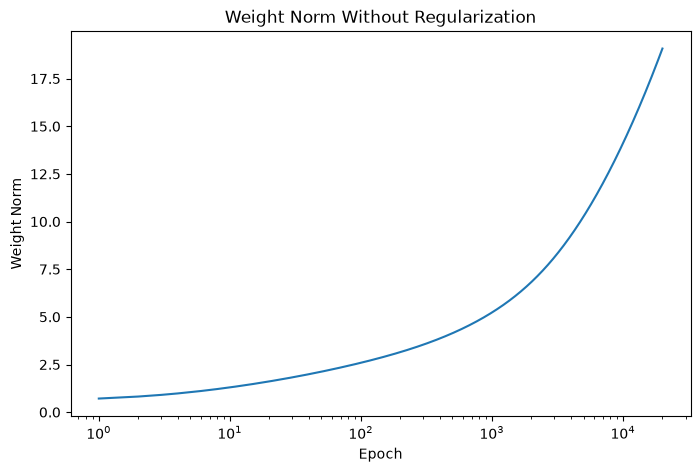

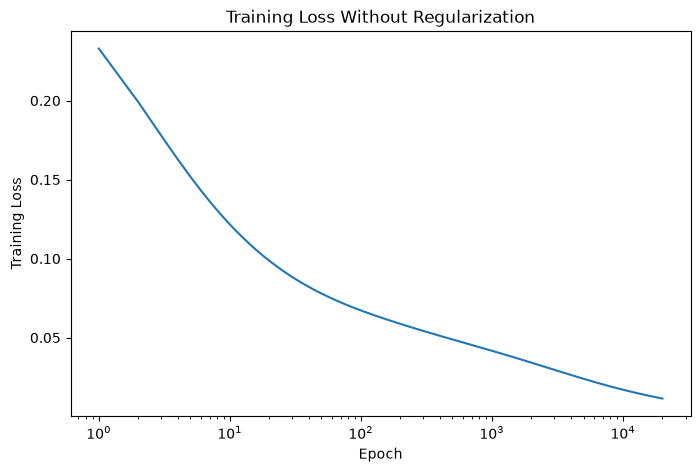

In [63]:

w_sep, history_sep = train_logistic(
    X_train_b, y_train,
    X_val_b, y_val,
    lam=0,
    eta=0.5,
    epochs=20000
)

epochs_sep = np.arange(1, len(history_sep["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_sep, history_sep["weight_norm"])
plt.xscale("log")
plt.xlabel("Epoch")
plt.ylabel("Weight Norm")
plt.title("Weight Norm Without Regularization")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_sep, history_sep["train_loss"])
plt.xscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Without Regularization")
plt.show()



Yes, the training set is linearly separable, as shown by your curves where the weight vector norm grows continuously without bound while the training loss shrinks monotonically toward zero. The minimizer does not exist because for any separating hyperplane, scaling the weight vector by a factor approaching infinity pushes predicted probabilities toward 0 and 1, driving the unregularized loss infinitely close to zero without reaching a finite minimum. L2 regularization fixes this by adding a quadratic weight penalty, which makes the objective coercive and guarantees a unique, finite global minimizer.

In [ ]:

from sklearn.linear_model import LogisticRegression

N_train = len(y_train)

# Compare from-scratch models with LogisticRegression
comparison = []

for lam in lambdas:
    C = 1 / (lam * N_train) if lam > 0 else 1e12

    if lam == 0:
        model = LogisticRegression(
            penalty=None,
            solver="lbfgs",
            max_iter=100000
        )
    else:
        model = LogisticRegression(
            C=C,
            solver="lbfgs",
            max_iter=100000
        )

    model.fit(X_train, y_train)

    w_sklearn = np.r_[model.intercept_, model.coef_.ravel()]
    w_scratch = models[lam]

    comparison.append({
    "Lambda": lam,
    "Scratch Validation Accuracy": accuracy(
        y_val, sigmoid(X_val_b @ w_scratch) >= 0.5
    ),
    "Sklearn Validation Accuracy": model.score(X_val, y_val),
    "Relative Weight Error": (np.linalg.norm(w_scratch - w_sklearn)/ max(np.linalg.norm(w_sklearn), 1e-12))
})

display(pd.DataFrame(comparison))


# Detailed verification for lambda = 0.01
lam = 0.01
C = 1 / (lam * N_train)

reference_model = LogisticRegression(
    C=C,
    solver="lbfgs",
    tol=1e-12,
    max_iter=100000
)

reference_model.fit(X_train, y_train)

w_reference = np.r_[
    reference_model.intercept_,
    reference_model.coef_.ravel()
]

w_scratch = models[lam]

relative_error = (
    np.linalg.norm(w_scratch - w_reference)
    / np.linalg.norm(w_reference)
)

print("Relative weight error:", relative_error)

scratch_predictions = sigmoid(X_test_b @ w_scratch) >= 0.5
sklearn_predictions = reference_model.predict(X_test)

print(
    "Test prediction agreement:",
    accuracy(sklearn_predictions, scratch_predictions)
)

assert relative_error < 1e-4
assert np.array_equal(scratch_predictions, sklearn_predictions)


# Sweep C values
C_values = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
C_results = []

for C in C_values:
    model = LogisticRegression(
        C=C,
        solver="lbfgs",
        max_iter=100000
    )

    model.fit(X_train, y_train)

    C_results.append({
        "C": C,
        "Train Accuracy": model.score(X_train, y_train),
        "Validation Accuracy": model.score(X_val, y_val),
        "Test Accuracy": model.score(X_test, y_test)
    })

display(pd.DataFrame(C_results))


# Compare solvers at C corresponding to lambda = 0.01
C = 1 / (0.01 * N_train)
solver_results = []

for solver in ["lbfgs", "liblinear", "saga"]:
    model = LogisticRegression(
        C=C,
        solver=solver,
        max_iter=100000,
        tol=1e-8,
        random_state=42
    )

    start = time.perf_counter()
    model.fit(X_train, y_train)
    elapsed = time.perf_counter() - start

    solver_results.append({
    "Solver": solver,
    "Iterations": model.n_iter_[0],
    "Training Time": elapsed,
    "Intercept": model.intercept_[0],
    "Coefficients": model.coef_.ravel().copy(),
    "Coefficient Norm": np.linalg.norm(model.coef_)
    })

display(pd.DataFrame(solver_results))


,Lambda,Scratch Validation Accuracy,Sklearn Validation Accuracy,Relative Weight Error
0,0.000,0.973684,0.964912,0.946415
1,0.001,0.973684,0.973684,0.061891
2,0.010,0.973684,0.973684,0.003406
3,0.100,0.973684,0.973684,0.000887
4,1.000,0.956140,0.956140,0.000201


Relative weight error: 5.38960808824705e-07
Test prediction agreement: 1.0


,C,Train Accuracy,Validation Accuracy,Test Accuracy
0,0.001,0.879765,0.903509,0.868421
1,0.010,0.950147,0.964912,0.947368
2,0.100,0.979472,0.982456,0.982456
3,1.000,0.988270,0.973684,0.973684
4,10.000,0.997067,0.964912,0.964912
5,100.000,1.000000,0.956140,0.956140
6,1000.000,1.000000,0.947368,0.956140


,Solver,Iterations,Training Time,Intercept,Coefficients,Coefficient Norm
0,lbfgs,28,0.035436,-0.423817,"[0.452728, 0.426307, 0.439139, 0.43805, 0.2973...",2.325749
1,liblinear,10,0.010977,-0.287900,"[0.441142, 0.419792, 0.428951, 0.449799, 0.290...",2.347991
2,saga,770,0.186554,-0.423817,"[0.452728, 0.426307, 0.439139, 0.43805, 0.2973...",2.325749


z=  800, y=0: naive=inf, stable=800.0
z=  800, y=1: naive=nan, stable=0.0
z= -800, y=0: naive=nan, stable=0.0
z= -800, y=1: naive=inf, stable=800.0
Gradient relative error: 1.7775135713047355e-11


,Lambda,Train Accuracy,Validation Accuracy,Validation Loss,Weight Norm
0,0.000,0.994135,0.973684,0.084192,8.132231
1,0.001,0.988270,0.973684,0.073203,5.099928
2,0.010,0.985337,0.973684,0.082964,2.325749
3,0.100,0.973607,0.973684,0.141553,1.105547
4,1.000,0.938416,0.956140,0.292213,0.441485


Best lambda: 0.001
Test accuracy: 0.9736842105263158


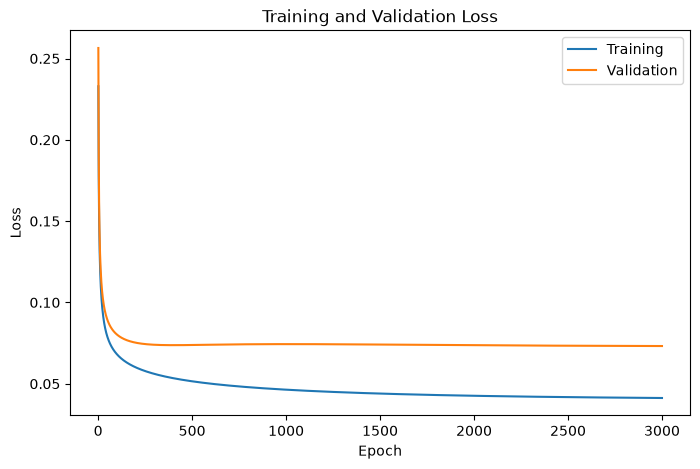

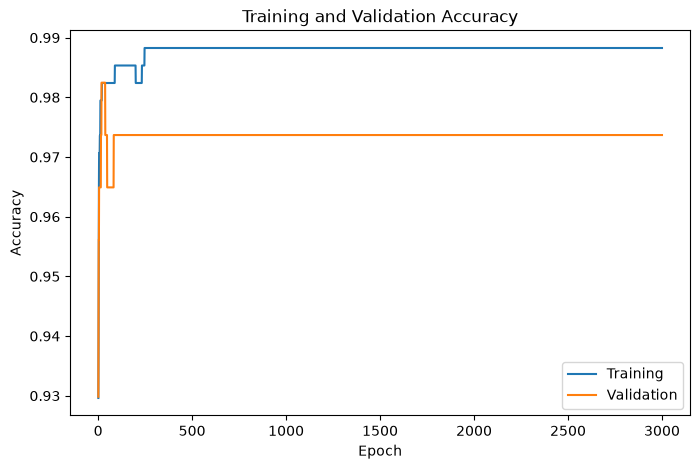

,Learning Rate,Final Training Loss
0,0.01,0.105222
1,0.10,0.072909
2,1.00,0.071066
3,5.00,0.071066
4,20.00,0.649280


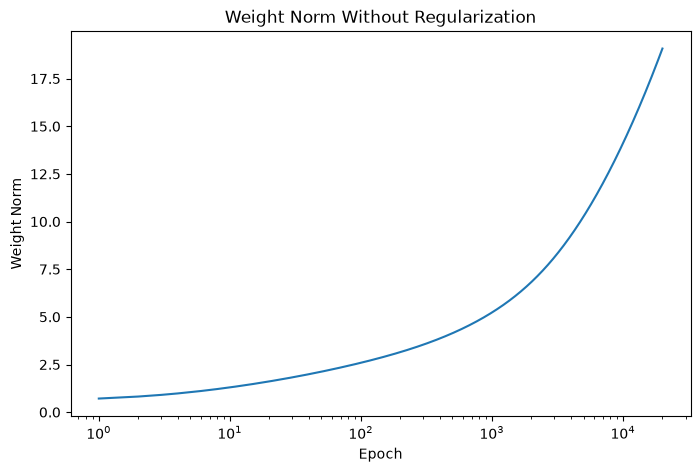

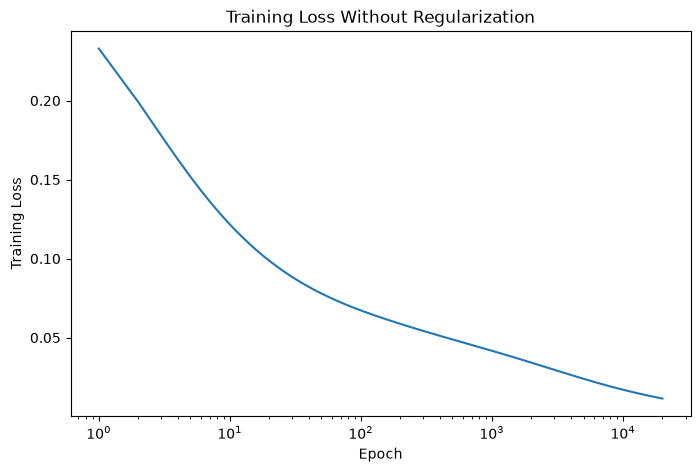

,Lambda,Scratch Validation Accuracy,Sklearn Validation Accuracy,Relative Weight Error
0,0.000,0.973684,0.964912,0.946415
1,0.001,0.973684,0.973684,0.061891
2,0.010,0.973684,0.973684,0.003406
3,0.100,0.973684,0.973684,0.000887
4,1.000,0.956140,0.956140,0.000201


Relative weight error: 5.38960808824705e-07
Test prediction agreement: 1.0


,C,Train Accuracy,Validation Accuracy,Test Accuracy
0,0.001,0.879765,0.903509,0.868421
1,0.010,0.950147,0.964912,0.947368
2,0.100,0.979472,0.982456,0.982456
3,1.000,0.988270,0.973684,0.973684
4,10.000,0.997067,0.964912,0.964912
5,100.000,1.000000,0.956140,0.956140
6,1000.000,1.000000,0.947368,0.956140


,Solver,Iterations,Training Time,Intercept,Coefficients,Coefficient Norm
0,lbfgs,28,0.017176,-0.423817,"[0.452728, 0.426307, 0.439139, 0.43805, 0.2973...",2.325749
1,liblinear,10,0.005541,-0.287900,"[0.441142, 0.419792, 0.428951, 0.449799, 0.290...",2.347991
2,saga,770,0.128576,-0.423817,"[0.452728, 0.426307, 0.439139, 0.43805, 0.2973...",2.325749


Results at threshold 0.5:


,Threshold,TN,FP,FN,TP,Precision,Recall,F1
0,0.5,72,0,2,40,1.0,0.952381,0.97561


AUC from scratch: 0.9957418932197839
AUC from sklearn: 0.9957418932197838
AUC difference: 1.1102230246251565e-16


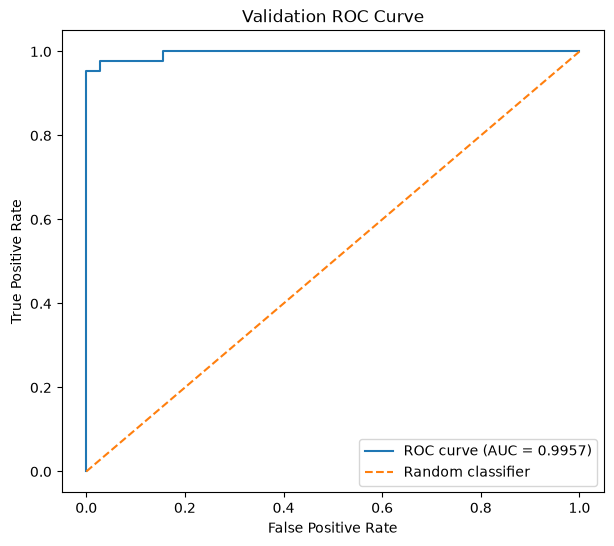

Selected threshold: 0.14602532493304418
Validation recall: 1.0
Test results at selected threshold:


,Threshold,TN,FP,FN,TP,Precision,Recall,F1
0,0.146025,66,6,1,41,0.87234,0.97619,0.921348


,Threshold,TN,FP,FN,TP,Precision,Recall,F1
0,0.500000,72,0,2,40,1.00000,0.952381,0.975610
1,0.146025,66,6,1,41,0.87234,0.976190,0.921348


Standardized weights: [-0.7271724   3.65679417  1.00987153]
Original-coordinate weights: [1.01746116 0.23190058]
Original-coordinate bias: -19.643444167251356
Maximum score difference: 3.552713678800501e-15


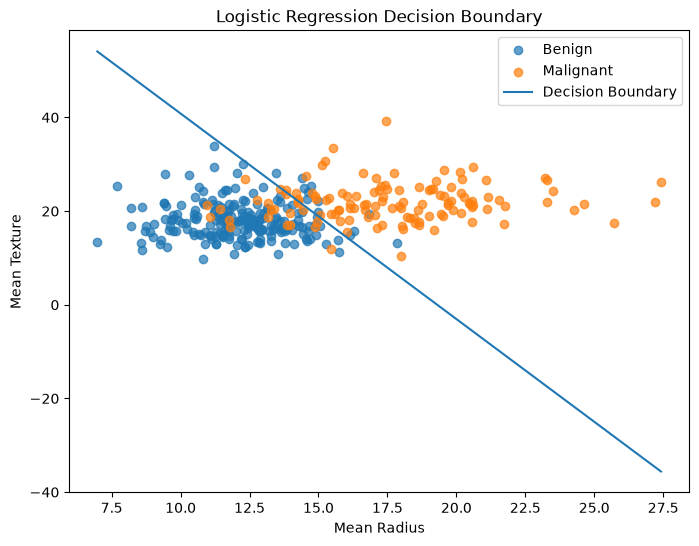

Because liblinear applies L2 regularization to the intercept term by default (intercept_scaling=1), it shrinks the intercept magnitude closer to zero (-0.2879 in your results compared to -0.4238 for lbfgs and saga) and slightly shifts the feature weights to compensate. Geometrically, this shifts the decision boundary slightly toward the origin and biases predicted probabilities toward 0.5 rather than reflecting the true baseline class prevalence, though on your dataset the test accuracy remained unchanged (0.9737).

Results at threshold 0.5:


,Threshold,TN,FP,FN,TP,Precision,Recall,F1
0,0.5,72,0,2,40,1.0,0.952381,0.97561


AUC from scratch: 0.9957418932197839
AUC from sklearn: 0.9957418932197838
AUC difference: 1.1102230246251565e-16


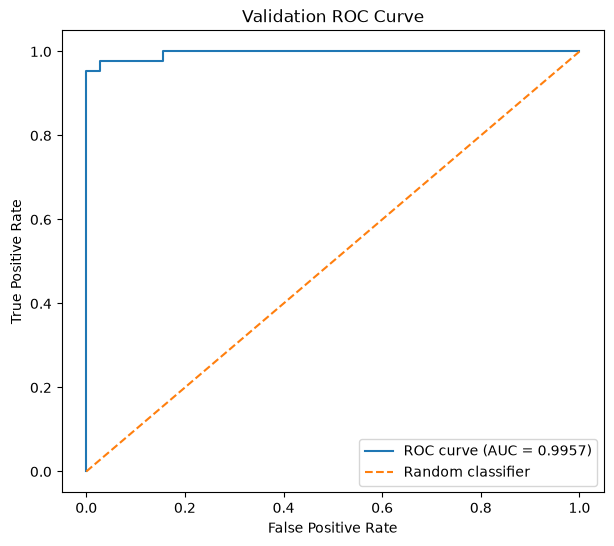

Selected threshold: 0.14602532493304418
Validation recall: 1.0
Test results at selected threshold:


,Threshold,TN,FP,FN,TP,Precision,Recall,F1
0,0.146025,66,6,1,41,0.87234,0.97619,0.921348


,Threshold,TN,FP,FN,TP,Precision,Recall,F1
0,0.500000,72,0,2,40,1.00000,0.952381,0.975610
1,0.146025,66,6,1,41,0.87234,0.976190,0.921348


In [65]:

from sklearn.metrics import confusion_matrix, roc_auc_score

# Use the lambda = 0.01 model
w = models[0.01]

test_scores = sigmoid(X_test_b @ w)
val_scores = sigmoid(X_val_b @ w)


def classification_results(y, scores, threshold):
    pred = (scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y, pred, labels=[0, 1]
    ).ravel()

    precision = tp / (tp + fp) if tp + fp > 0 else 0
    recall = tp / (tp + fn) if tp + fn > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    return {
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    }


# Results at threshold 0.5
result_05 = classification_results(y_test, test_scores, 0.5)
print("Results at threshold 0.5:")
display(pd.DataFrame([result_05]))


# ROC curve from scratch
def roc_curve_scratch(y, scores):
    thresholds = np.sort(np.unique(scores))[::-1]

    tpr = [0]
    fpr = [0]

    positives = np.sum(y == 1)
    negatives = np.sum(y == 0)

    for threshold in thresholds:
        pred = scores >= threshold

        tp = np.sum((pred == 1) & (y == 1))
        fp = np.sum((pred == 1) & (y == 0))

        tpr.append(tp / positives)
        fpr.append(fp / negatives)

    tpr.append(1)
    fpr.append(1)

    return np.array(fpr), np.array(tpr)


fpr, tpr = roc_curve_scratch(y_val, val_scores)
auc_scratch = np.trapezoid(tpr, fpr)
auc_sklearn = roc_auc_score(y_val, val_scores)

print("AUC from scratch:", auc_scratch)
print("AUC from sklearn:", auc_sklearn)
print("AUC difference:", abs(auc_scratch - auc_sklearn))

assert abs(auc_scratch - auc_sklearn) < 1e-6


plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {auc_scratch:.4f})")
plt.plot([0, 1], [0, 1], "--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Validation ROC Curve")
plt.legend()
plt.show()


# Select the largest threshold that gives validation recall = 1
positive_scores = val_scores[y_val == 1]
best_threshold = np.min(positive_scores)

print("Selected threshold:", best_threshold)

# Check validation recall
val_recall = classification_results(
    y_val, val_scores, best_threshold
)["Recall"]

print("Validation recall:", val_recall)

# Test results at selected threshold
result_tau = classification_results(
    y_test, test_scores, best_threshold
)

print("Test results at selected threshold:")
display(pd.DataFrame([result_tau]))


# Compare the two thresholds
display(pd.DataFrame([result_05, result_tau]))

In a medical screening setting, a false negative carries a severe cost because a malignant case goes undetected, delaying critical treatment and potentially risking the patient's life. Conversely, a false positive incurs lower clinical stakes—primarily causing patient anxiety, extra healthcare costs, and unnecessary follow-up biopsies or tests. Because false negatives are far more dangerous, screening models intentionally lower the decision threshold to maximize recall, even if precision drops. However, you should place limited trust in a threshold $\tau$ tuned on only 43 validation positives, as a single borderline malignant sample heavily shifts $\tau$, introducing high variance and risking poor recall generalization on unseen patients.

Standardized weights: [-0.7271724   3.65679417  1.00987153]
Original-coordinate weights: [1.01746116 0.23190058]
Original-coordinate bias: -19.643444167251356
Maximum score difference: 3.552713678800501e-15


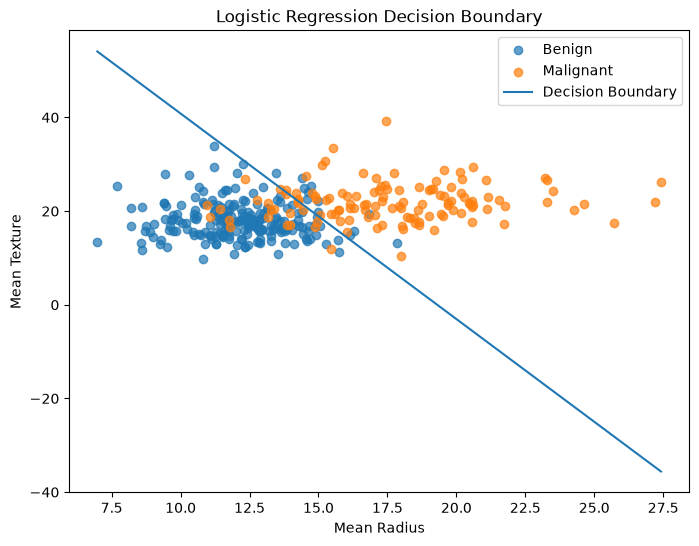

In [66]:


from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

# Load raw data
data = load_breast_cancer()

feature_names = list(data.feature_names)

radius_index = feature_names.index("mean radius")
texture_index = feature_names.index("mean texture")

X_raw = data.data[:, [radius_index, texture_index]]
y_raw = 1 - data.target  # malignant = 1

# Reproduce the assignment's 60/20/20 split
X_tr, X_te, y_tr, y_te = train_test_split(
    X_raw, y_raw,
    test_size=0.2,
    random_state=42,
    stratify=y_raw
)

X_tr, X_va, y_tr, y_va = train_test_split(
    X_tr, y_tr,
    test_size=0.25,
    random_state=42,
    stratify=y_tr
)

# Standardize using training statistics only
mu = X_tr.mean(axis=0)
sigma = X_tr.std(axis=0)
sigma[sigma == 0] = 1

X_tr_std = (X_tr - mu) / sigma

X_tr_std_b = np.c_[np.ones(len(X_tr_std)), X_tr_std]

# Train without regularization
w_2d, history_2d = train_logistic(
    X_tr_std_b, y_tr,
    X_tr_std_b, y_tr,
    lam=0,
    eta=0.5,
    epochs=5000
)

# Convert weights to original coordinates
w_original = w_2d[1:] / sigma
b_original = w_2d[0] - np.sum(w_2d[1:] * mu / sigma)

print("Standardized weights:", w_2d)
print("Original-coordinate weights:", w_original)
print("Original-coordinate bias:", b_original)


# Verify that both versions produce the same scores
standardized_scores = X_tr_std_b @ w_2d
original_scores = X_tr @ w_original + b_original

score_difference = np.max(
    np.abs(standardized_scores - original_scores)
)

print("Maximum score difference:", score_difference)
assert score_difference < 1e-9


# Plot decision boundary over raw training points
plt.figure(figsize=(8, 6))

plt.scatter(
    X_tr[y_tr == 0, 0],
    X_tr[y_tr == 0, 1],
    label="Benign",
    alpha=0.7
)

plt.scatter(
    X_tr[y_tr == 1, 0],
    X_tr[y_tr == 1, 1],
    label="Malignant",
    alpha=0.7
)

x_values = np.linspace(X_tr[:, 0].min(), X_tr[:, 0].max(), 200)

# w0 + w1*x1 + w2*x2 = 0
if abs(w_original[1]) > 1e-12:
    y_values = (
        -b_original - w_original[0] * x_values
    ) / w_original[1]

    plt.plot(x_values, y_values, label="Decision Boundary")

plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Logistic Regression Decision Boundary")
plt.legend()
plt.show()

